# Proyecto Final - Matemáticas Discretas con Aplicaciones
## Red de Bicicletas Compartidas LOBOBICI (Ciudad Universitaria, BUAP)

### Sección 1: Definición, Clasificación y Visualización

In [47]:
import csv
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

# CARGA DINÁMICA DEL GRAFO BASE G = (V, E) DESDE LOS CSV
G = nx.Graph()

with open("data/estaciones_cu.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        nid = int(row["id"])
        G.add_node(
            nid,
            nombre=row["nombre"],
            lat=float(row["lat"]),
            lon=float(row["lon"]),
            pos=(float(row["x_m"]), float(row["y_m"])),
            abierta=bool(int(row["abierta_1530"])),
            bicis=int(row["bicis_1530"]),
        )

with open("data/aristas_cu.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        G.add_edge(
            int(row["origen"]),
            int(row["destino"]),
            dist_euclidiana_m=float(row["dist_euclidiana_m"]),
            dist_ruta_m=float(row["dist_ruta_m"]),
            fuente_ruta=row["fuente_ruta"],
        )

#VERIFICACIÓN DINÁMICA DE CLASIFICACIÓN TEÓRICA
n_nodos = G.number_of_nodes()
n_aristas = G.number_of_edges()
es_simple = (nx.number_of_selfloops(G) == 0) and (not G.is_multigraph())
abiertas = [n for n, d in G.nodes(data=True) if d["abierta"]]
cerradas = [n for n, d in G.nodes(data=True) if not d["abierta"]]
total_bicis = sum(d["bicis"] for _, d in G.nodes(data=True))

print("=== RESUMEN Y CLASIFICACIÓN TEÓRICA DE G = (V, E) ===")
print(f"Vértices |V|            : {n_nodos} (requisito >= 15: {'OK' if n_nodos >= 15 else 'NO'})")
print(f"Aristas  |E|            : {n_aristas} (requisito >= 22: {'OK' if n_aristas >= 22 else 'NO'})")
print(f"Dirigido                : {G.is_directed()} (No dirigido)")
print(f"Multigrafo              : {G.is_multigraph()}")
print(f"Grafo simple            : {es_simple}")
print(f"Conexo                  : {nx.is_connected(G)} (componentes: {nx.number_connected_components(G)})")
print(f"Ponderado               : Sí (peso principal: dist_ruta_m en metros)")
print(f"Corte 15:30 hrs         : {len(abiertas)} abiertas ({total_bicis} bicis) | {len(cerradas)} cerradas")

=== RESUMEN Y CLASIFICACIÓN TEÓRICA DE G = (V, E) ===
Vértices |V|            : 21 (requisito >= 15: OK)
Aristas  |E|            : 29 (requisito >= 22: OK)
Dirigido                : False (No dirigido)
Multigrafo              : False
Grafo simple            : True
Conexo                  : True (componentes: 1)
Ponderado               : Sí (peso principal: dist_ruta_m en metros)
Corte 15:30 hrs         : 8 abiertas (356 bicis) | 13 cerradas


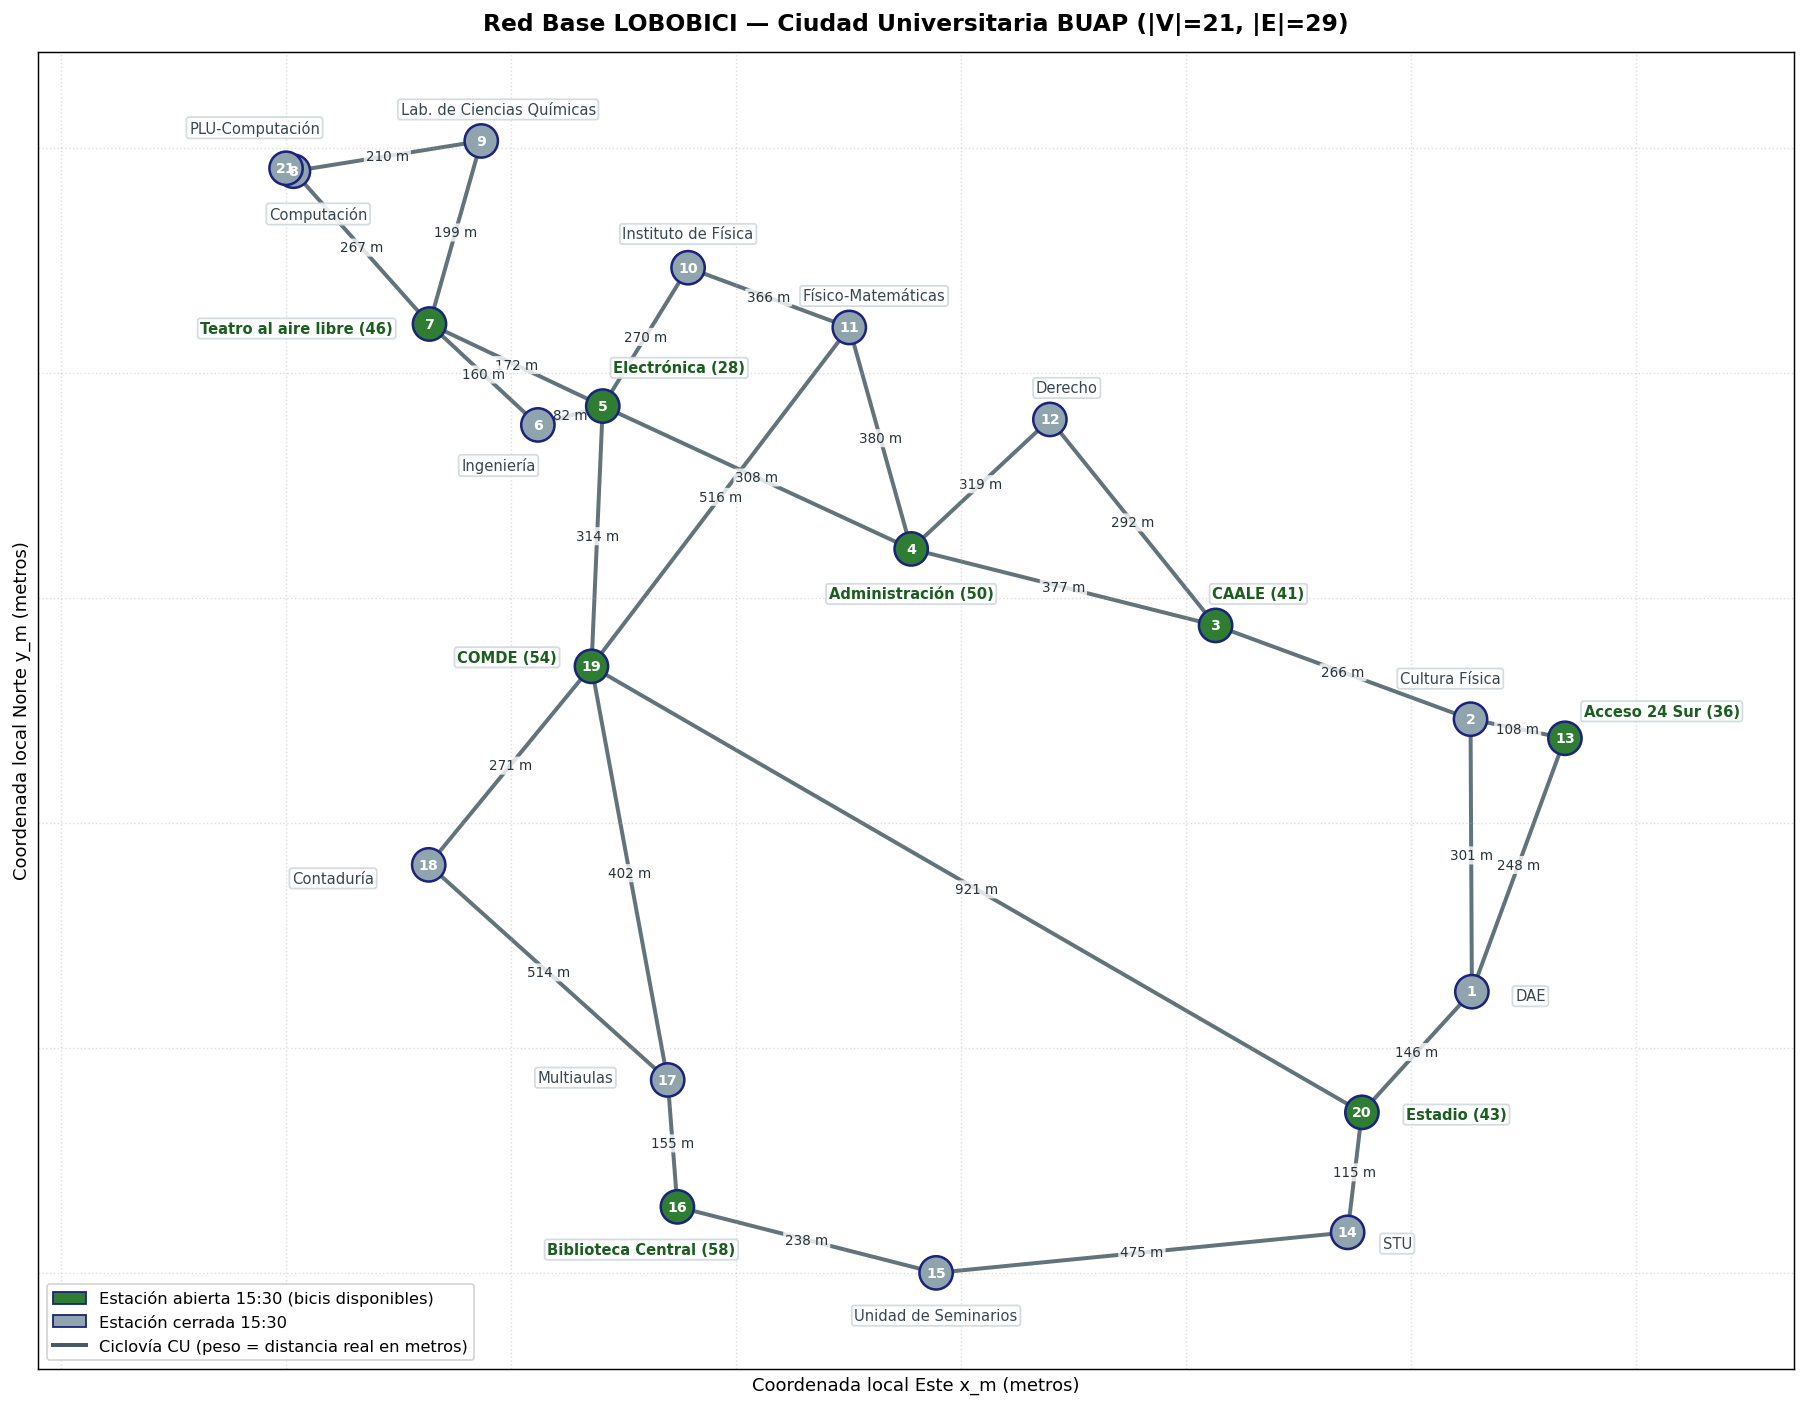

In [48]:
# VISUALIZACIÓN DE LA RED BASE LOBOBICI CU (MATPLOTLIB Y NETWORKX)
pos = nx.get_node_attributes(G, "pos")

# Desplazamientos finos de etiquetas (dx, dy en metros) para evitar empalmes
label_offsets = {
    1:  (52,  -4),
    2:  (-18, 36),
    3:  (38,  28),
    4:  (0,  -40),
    5:  (68,  34),
    6:  (-35,-36),
    7:  (-118,-4),
    8:  (22, -38),
    9:  (15,  28),
    10: (0,   30),
    11: (22,  28),
    12: (15,  28),
    13: (86,  24),
    14: (44, -10),
    15: (0,  -38),
    16: (-32,-38),
    17: (-82,  2),
    18: (-85,-12),
    19: (-75,  8),
    20: (84,  -2),
    21: (-28, 36),
}

fig, ax = plt.subplots(figsize=(14, 11), dpi=130)

# Aristas
nx.draw_networkx_edges(
    G, pos, ax=ax,
    edge_color="#455A64",
    width=2.2,
    alpha=0.85,
)

# Pesos de aristas (distancia real por ciclovía en metros)
edge_labels = {(u, v): f"{d['dist_ruta_m']:.0f} m" for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=7.5,
    font_color="#263238",
    rotate=False,
    bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.8),
    ax=ax,
)

# Nodos coloreados dinámicamente según estado a las 15:30
node_colors = ["#2E7D32" if G.nodes[n]["abierta"] else "#90A4AE" for n in G.nodes()]
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_color=node_colors,
    edgecolors="#1A237E",
    linewidths=1.4,
    node_size=340,
)

# Número de estación dentro del nodo
nx.draw_networkx_labels(
    G, pos, ax=ax,
    font_size=7.8,
    font_weight="bold",
    font_color="white",
)

# Nombres claros junto a cada estación
for nid, (x, y) in pos.items():
    dx, dy = label_offsets.get(nid, (18, 18))
    nombre = G.nodes[nid]["nombre"]
    if G.nodes[nid]["abierta"]:
        texto = f"{nombre} ({G.nodes[nid]['bicis']})"
        color_txt = "#1B5E20"
    else:
        texto = nombre
        color_txt = "#37474F"
    ax.text(
        x + dx, y + dy, texto,
        fontsize=8.2,
        fontweight="semibold" if G.nodes[nid]["abierta"] else "normal",
        color=color_txt,
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.18", facecolor="white", edgecolor="#CFD8DC", alpha=0.88),
    )

# Leyenda y formato
legend_items = [
    mpatches.Patch(facecolor="#2E7D32", edgecolor="#1A237E", label="Estación abierta 15:30 (bicis disponibles)"),
    mpatches.Patch(facecolor="#90A4AE", edgecolor="#1A237E", label="Estación cerrada 15:30"),
    mlines.Line2D([], [], color="#455A64", linewidth=2.2, label="Ciclovía CU (peso = distancia real en metros)"),
]
ax.legend(handles=legend_items, loc="lower left", frameon=True, fontsize=9)
ax.set_title(
    f"Red Base LOBOBICI — Ciudad Universitaria BUAP (|V|={G.number_of_nodes()}, |E|={G.number_of_edges()})",
    fontsize=13, fontweight="bold", pad=12,
)
ax.set_xlabel("Coordenada local Este x_m (metros)", fontsize=10)
ax.set_ylabel("Coordenada local Norte y_m (metros)", fontsize=10)
ax.set_aspect("equal")
ax.set_xlim(-220, 1340)
ax.set_ylim(-85, 1085)
ax.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout()
plt.show()

=== VALIDACIÓN DEL MODELO BIPARTITO B = (U ∪ W, E_B) ===
|U| (Abiertas / Oferta)   : 8
|W| (Cerradas / Demanda)  : 13
|E_B| (Asignaciones K=2) : 26
nx.is_bipartite(B)        : True
Aristas dentro de U o W   : 0 en U, 0 en W
¿Existen ciclos impares?  : False (ciclos base encontrados: 6)

--- Asignación de cobertura (Cerrada -> Abierta principal / respaldo) ---
   1 DAE                        -> #1 20-Estadio (146 m) | #2 13-Acceso 24 Sur (248 m)
   2 Cultura Física             -> #1 13-Acceso 24 Sur (108 m) | #2 3-CAALE (266 m)
   6 Ingeniería                 -> #1 5-Electrónica (82 m) | #2 7-Teatro al aire libre (160 m)
   8 Computación                -> #1 7-Teatro al aire libre (267 m) | #2 5-Electrónica (440 m)
   9 Lab. de Ciencias Químicas  -> #1 7-Teatro al aire libre (199 m) | #2 5-Electrónica (371 m)
  10 Instituto de Física        -> #1 5-Electrónica (270 m) | #2 7-Teatro al aire libre (442 m)
  11 Físico-Matemáticas         -> #1 4-Administración (380 m) | #2 19-COMDE (516 m)

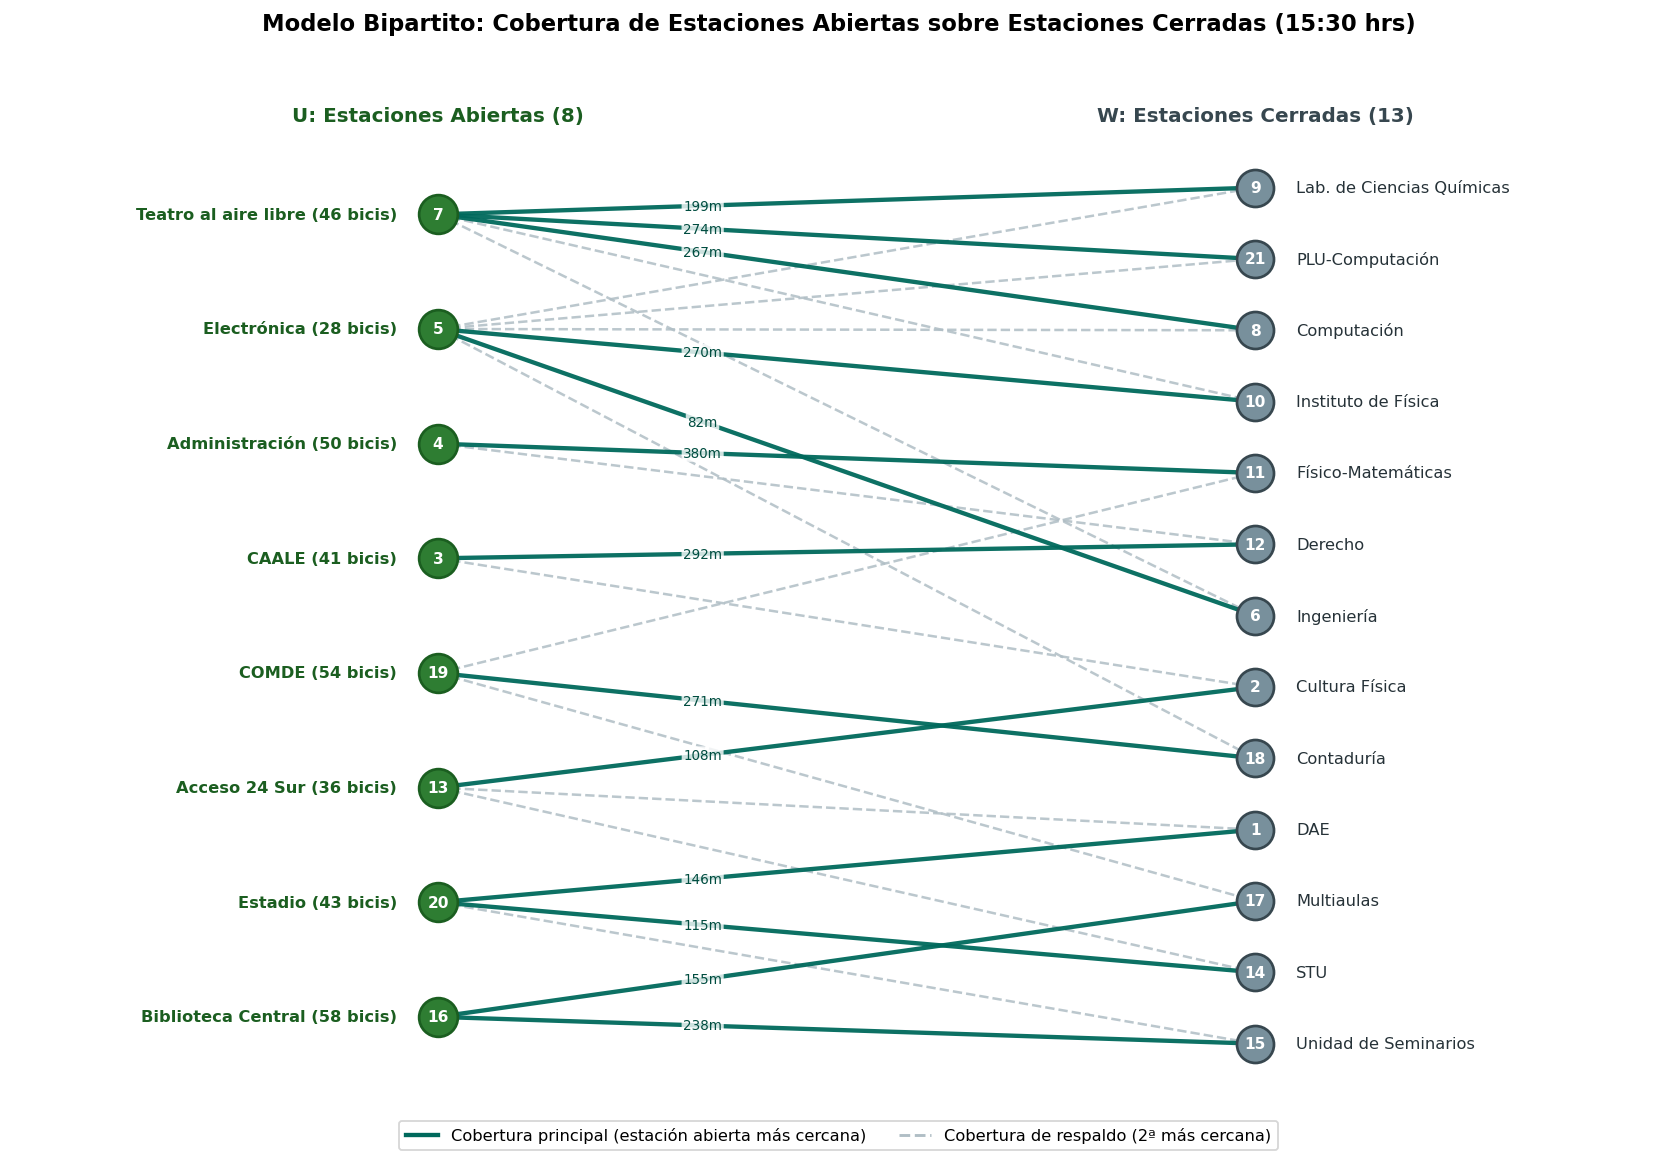

In [49]:
# Modelo bipartito B = (U, W, E_B)
# U: estaciones abiertas (15:30), W: estaciones cerradas
# Cada estación cerrada se conecta con sus K abiertas más cercanas por Dijkstra

K_OPCIONES = 2  # 2 = principal + respaldo

U = sorted([n for n, d in G.nodes(data=True) if d["abierta"]])
W = sorted([n for n, d in G.nodes(data=True) if not d["abierta"]])

B = nx.Graph()
for u in U:
    B.add_node(u, bipartite=0, nombre=G.nodes[u]["nombre"], bicis=G.nodes[u]["bicis"])
for w in W:
    B.add_node(w, bipartite=1, nombre=G.nodes[w]["nombre"], bicis=0)

# Cálculo dinámico de distancias más cortas en G (Dijkstra)
for w in W:
    distancias = nx.single_source_dijkstra_path_length(G, w, weight="dist_ruta_m")
    candidatas = sorted([(distancias[u], u) for u in U if u in distancias])
    for prioridad, (dist_m, u) in enumerate(candidatas[:K_OPCIONES], start=1):
        B.add_edge(u, w, dist_ruta_m=round(dist_m, 1), prioridad=prioridad)

# Validación de bipartición
es_bipartito = nx.is_bipartite(B)
aristas_internas_U = [(a, b) for a, b in B.edges() if a in U and b in U]
aristas_internas_W = [(a, b) for a, b in B.edges() if a in W and b in W]
ciclos_base = nx.cycle_basis(B)
hay_ciclo_impar = any(len(c) % 2 == 1 for c in ciclos_base)

print("=== VALIDACIÓN DEL MODELO BIPARTITO B = (U ∪ W, E_B) ===")
print(f"|U| (Abiertas / Oferta)   : {len(U)}")
print(f"|W| (Cerradas / Demanda)  : {len(W)}")
print(f"|E_B| (Asignaciones K={K_OPCIONES}) : {B.number_of_edges()}")
print(f"nx.is_bipartite(B)        : {es_bipartito}")
print(f"Aristas dentro de U o W   : {len(aristas_internas_U)} en U, {len(aristas_internas_W)} en W")
print(f"¿Existen ciclos impares?  : {hay_ciclo_impar} (ciclos base encontrados: {len(ciclos_base)})")

print("\n--- Asignación de cobertura (Cerrada -> Abierta principal / respaldo) ---")
for w in W:
    vecinas = sorted(B[w].items(), key=lambda item: item[1]["prioridad"])
    resumen = " | ".join(
        f"#{d['prioridad']} {u}-{G.nodes[u]['nombre']} ({d['dist_ruta_m']:.0f} m)"
        for u, d in vecinas
    )
    print(f"  {w:2d} {G.nodes[w]['nombre']:26s} -> {resumen}")

# Gráfica del grafo bipartito en dos columnas
# Ordenamos cada columna de Norte a Sur (mayor y_m arriba) para reducir cruces
U_ord = sorted(U, key=lambda n: G.nodes[n]["pos"][1], reverse=True)
W_ord = sorted(W, key=lambda n: G.nodes[n]["pos"][1], reverse=True)

pos_B = {}
y_U = np.linspace(0.95, 0.05, len(U_ord))
y_W = np.linspace(0.98, 0.02, len(W_ord))
for u, y in zip(U_ord, y_U):
    pos_B[u] = (0.0, y)
for w, y in zip(W_ord, y_W):
    pos_B[w] = (1.0, y)

fig, ax = plt.subplots(figsize=(13, 9), dpi=130)

aristas_p1 = [(u, v) for u, v, d in B.edges(data=True) if d["prioridad"] == 1]
aristas_p2 = [(u, v) for u, v, d in B.edges(data=True) if d["prioridad"] == 2]

nx.draw_networkx_edges(B, pos_B, edgelist=aristas_p2, edge_color="#B0BEC5", width=1.4, style="--", alpha=0.85, ax=ax)
nx.draw_networkx_edges(B, pos_B, edgelist=aristas_p1, edge_color="#00695C", width=2.4, alpha=0.95, ax=ax)

# Etiquetas de distancia sobre aristas principales (prioridad 1)
labels_p1 = {(u, v): f"{B[u][v]['dist_ruta_m']:.0f}m" for u, v in aristas_p1}
nx.draw_networkx_edge_labels(
    B, pos_B,
    edge_labels=labels_p1,
    label_pos=0.32,
    font_size=7.5,
    font_color="#004D40",
    rotate=False,
    bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none", alpha=0.8),
    ax=ax,
)

nx.draw_networkx_nodes(B, pos_B, nodelist=U_ord, node_color="#2E7D32", edgecolors="#1B5E20", node_size=460, linewidths=1.5, ax=ax)
nx.draw_networkx_nodes(B, pos_B, nodelist=W_ord, node_color="#78909C", edgecolors="#37474F", node_size=420, linewidths=1.5, ax=ax)
nx.draw_networkx_labels(B, pos_B, font_size=8.5, font_weight="bold", font_color="white", ax=ax)

# Nombres claros afuera de cada columna
for u in U_ord:
    x, y = pos_B[u]
    ax.text(
        x - 0.05, y,
        f"{G.nodes[u]['nombre']} ({G.nodes[u]['bicis']} bicis)",
        ha="right", va="center", fontsize=9, fontweight="semibold", color="#1B5E20",
    )
for w in W_ord:
    x, y = pos_B[w]
    ax.text(
        x + 0.05, y,
        G.nodes[w]["nombre"],
        ha="left", va="center", fontsize=9, color="#263238",
    )

ax.text(0.0, 1.05, "U: Estaciones Abiertas (8)", ha="center", va="bottom", fontsize=11, fontweight="bold", color="#1B5E20")
ax.text(1.0, 1.05, "W: Estaciones Cerradas (13)", ha="center", va="bottom", fontsize=11, fontweight="bold", color="#37474F")

legend_B = [
    mlines.Line2D([], [], color="#00695C", linewidth=2.4, label="Cobertura principal (estación abierta más cercana)"),
    mlines.Line2D([], [], color="#B0BEC5", linewidth=1.6, linestyle="--", label="Cobertura de respaldo (2ª más cercana)"),
]
ax.legend(handles=legend_B, loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=True, fontsize=9)
ax.set_title("Modelo Bipartito: Cobertura de Estaciones Abiertas sobre Estaciones Cerradas (15:30 hrs)", fontsize=12.5, fontweight="bold", pad=28)
ax.set_xlim(-0.52, 1.50)
ax.set_ylim(-0.04, 1.10)
ax.axis("off")
plt.tight_layout()
plt.show()

### Sección 2: Subgrafos y Representación Matricial


=== Subgrafo 1: Estaciones Abiertas (15:30 hrs) ===
Vértices |V(H)|      : 8
Aristas  |E(H)|      : 5
Conexo               : False (componentes conexas: 3)
Nodos aislados en H  : 13-Acceso 24 Sur, 16-Biblioteca Central

=== Subgrafo 2: Estaciones Cerradas (15:30 hrs) ===
Vértices |V(H)|      : 13
Aristas  |E(H)|      : 6
Conexo               : False (componentes conexas: 7)
Nodos aislados en H  : 6-Ingeniería, 12-Derecho



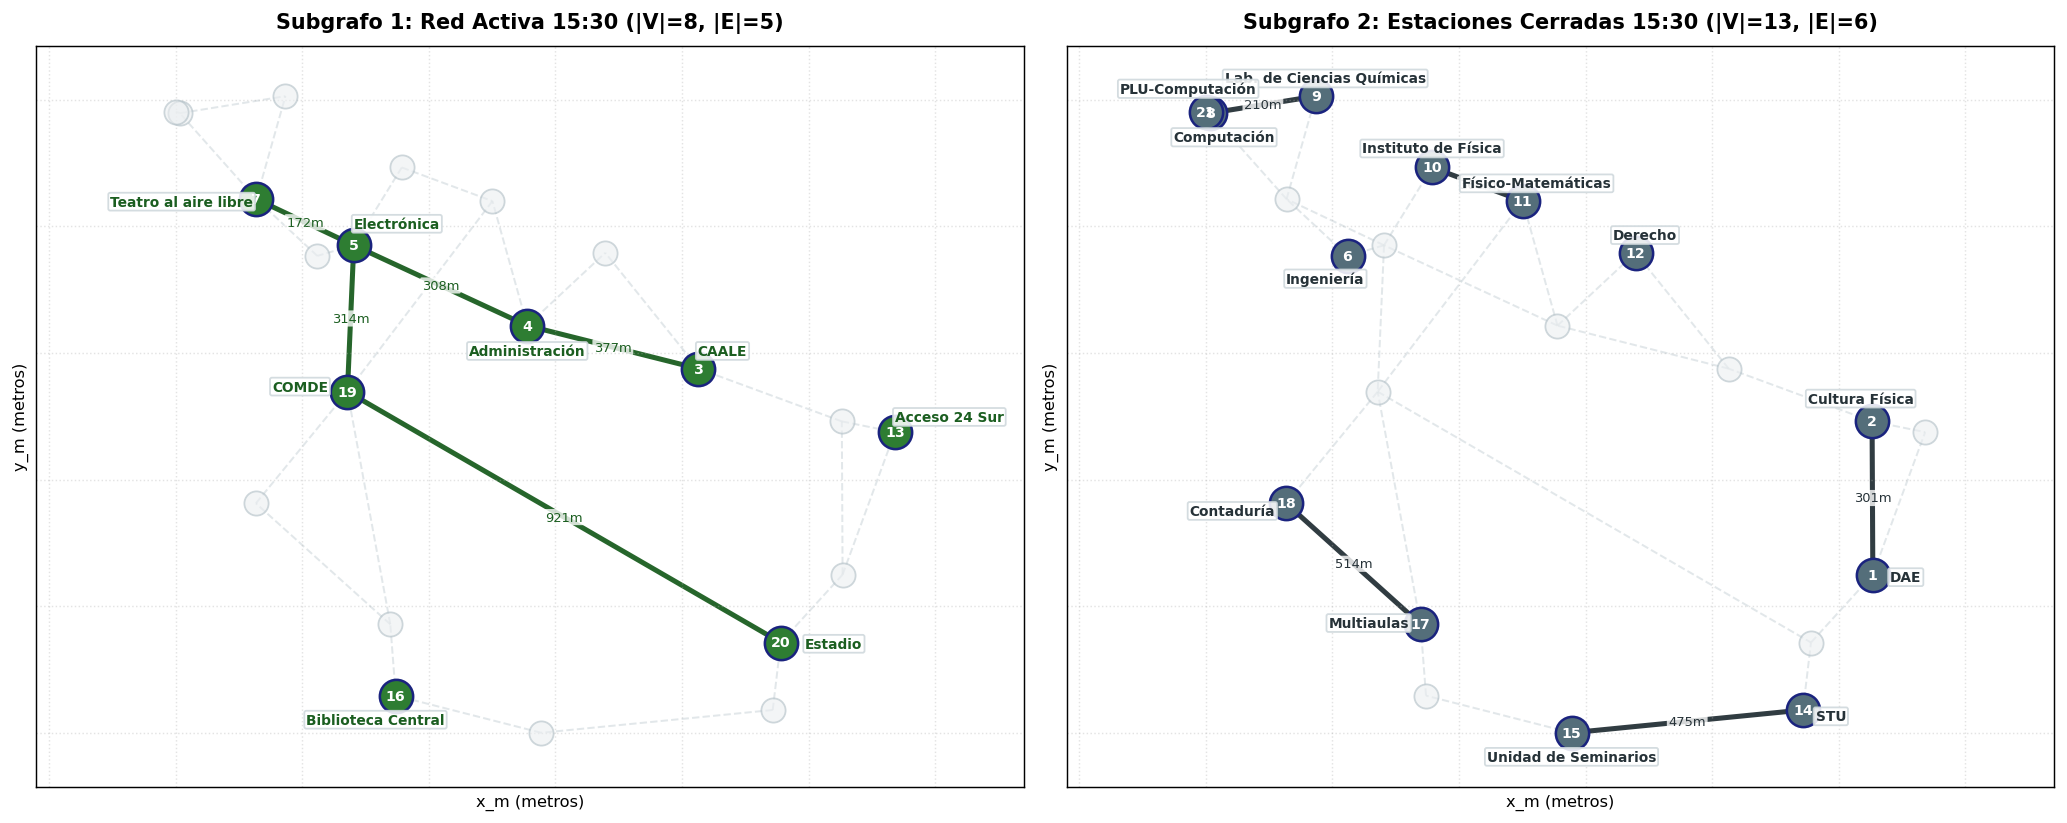

In [50]:
#OBTENCIÓN DINÁMICA DE DOS SUBGRAFOS RELEVANTES DE G
#    H_abiertas : Subsistema activo en el corte de las 15:30 hrs
#    H_cerradas : Zonas sin servicio directo a las 15:30 hrs
nodos_abiertos = sorted([n for n, d in G.nodes(data=True) if d["abierta"]])
nodos_cerrados = sorted([n for n, d in G.nodes(data=True) if not d["abierta"]])

H_abiertas = G.subgraph(nodos_abiertos).copy()
H_cerradas = G.subgraph(nodos_cerrados).copy()

for titulo, H in [
    ("Subgrafo 1: Estaciones Abiertas (15:30 hrs)", H_abiertas),
    ("Subgrafo 2: Estaciones Cerradas (15:30 hrs)", H_cerradas),
]:
    aislados = [f"{n}-{H.nodes[n]['nombre']}" for n in sorted(H.nodes()) if H.degree(n) == 0]
    comps = nx.number_connected_components(H)
    print(f"=== {titulo} ===")
    print(f"Vértices |V(H)|      : {H.number_of_nodes()}")
    print(f"Aristas  |E(H)|      : {H.number_of_edges()}")
    print(f"Conexo               : {nx.is_connected(H)} (componentes conexas: {comps})")
    print(f"Nodos aislados en H  : {', '.join(aislados) if aislados else 'Ninguno'}\n")

# Gráfica comparativa de ambos subgrafos sobre la red base
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), dpi=130)

configs = [
    (
        axes[0], H_abiertas, "#2E7D32", "#1B5E20",
        f"Subgrafo 1: Red Activa 15:30 (|V|={H_abiertas.number_of_nodes()}, |E|={H_abiertas.number_of_edges()})"
    ),
    (
        axes[1], H_cerradas, "#546E7A", "#263238",
        f"Subgrafo 2: Estaciones Cerradas 15:30 (|V|={H_cerradas.number_of_nodes()}, |E|={H_cerradas.number_of_edges()})"
    ),
]

for ax, H, color_nodo, color_arista, titulo in configs:
    # Fondo tenue con el grafo completo G como referencia espacial
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#CFD8DC", width=1.1, style="--", alpha=0.6)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#ECEFF1", edgecolors="#B0BEC5", node_size=180, alpha=0.6)

    # Subgrafo inducido H resaltado
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color=color_arista, width=2.8, alpha=0.95)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_color=color_nodo, edgecolors="#1A237E", linewidths=1.4, node_size=340)
    nx.draw_networkx_labels(H, pos, ax=ax, font_size=7.8, font_weight="bold", font_color="white")

    # Etiquetas de distancia en las aristas de H
    e_labels = {(u, v): f"{d['dist_ruta_m']:.0f}m" for u, v, d in H.edges(data=True)}
    nx.draw_networkx_edge_labels(
        H, pos, edge_labels=e_labels, font_size=7.2, font_color=color_arista,
        rotate=False, bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none", alpha=0.8), ax=ax
    )

    # Nombres de los nodos pertenecientes al subgrafo
    for nid in H.nodes():
        x, y = pos[nid]
        dx, dy = label_offsets.get(nid, (18, 18))
        ax.text(
            x + dx, y + dy, H.nodes[nid]["nombre"],
            fontsize=7.6, fontweight="semibold", color=color_arista,
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.14", facecolor="white", edgecolor="#CFD8DC", alpha=0.88),
        )

    ax.set_title(titulo, fontsize=11.5, fontweight="bold", pad=10)
    ax.set_xlabel("x_m (metros)", fontsize=9)
    ax.set_ylabel("y_m (metros)", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xlim(-220, 1340)
    ax.set_ylim(-85, 1085)
    ax.grid(True, linestyle=":", alpha=0.35)

plt.tight_layout()
plt.show()

=== MATRIZ DE ADYACENCIA PONDERADA W (dist_ruta_m en metros) ===
Dimensión |V| x |V|   : 21 x 21
Simétrica (W = W^T)   : True (grafo no dirigido)
Diagonal de ceros     : True (grafo simple)
Entradas > 0          : 58 (= 2|E| = 58)
Longitud total de red : 8398.7 m

       1    2    3    4    5    6    7    8    9   10   11   12   13   14   15   16   17   18   19   20   21
   ---------------------------------------------------------------------------------------------------------
 1 |   0  301    0    0    0    0    0    0    0    0    0    0  248    0    0    0    0    0    0  146    0
 2 | 301    0  266    0    0    0    0    0    0    0    0    0  108    0    0    0    0    0    0    0    0
 3 |   0  266    0  377    0    0    0    0    0    0    0  292    0    0    0    0    0    0    0    0    0
 4 |   0    0  377    0  308    0    0    0    0    0  380  319    0    0    0    0    0    0    0    0    0
 5 |   0    0    0  308    0   82  172    0    0  270    0    0    0    0    0   

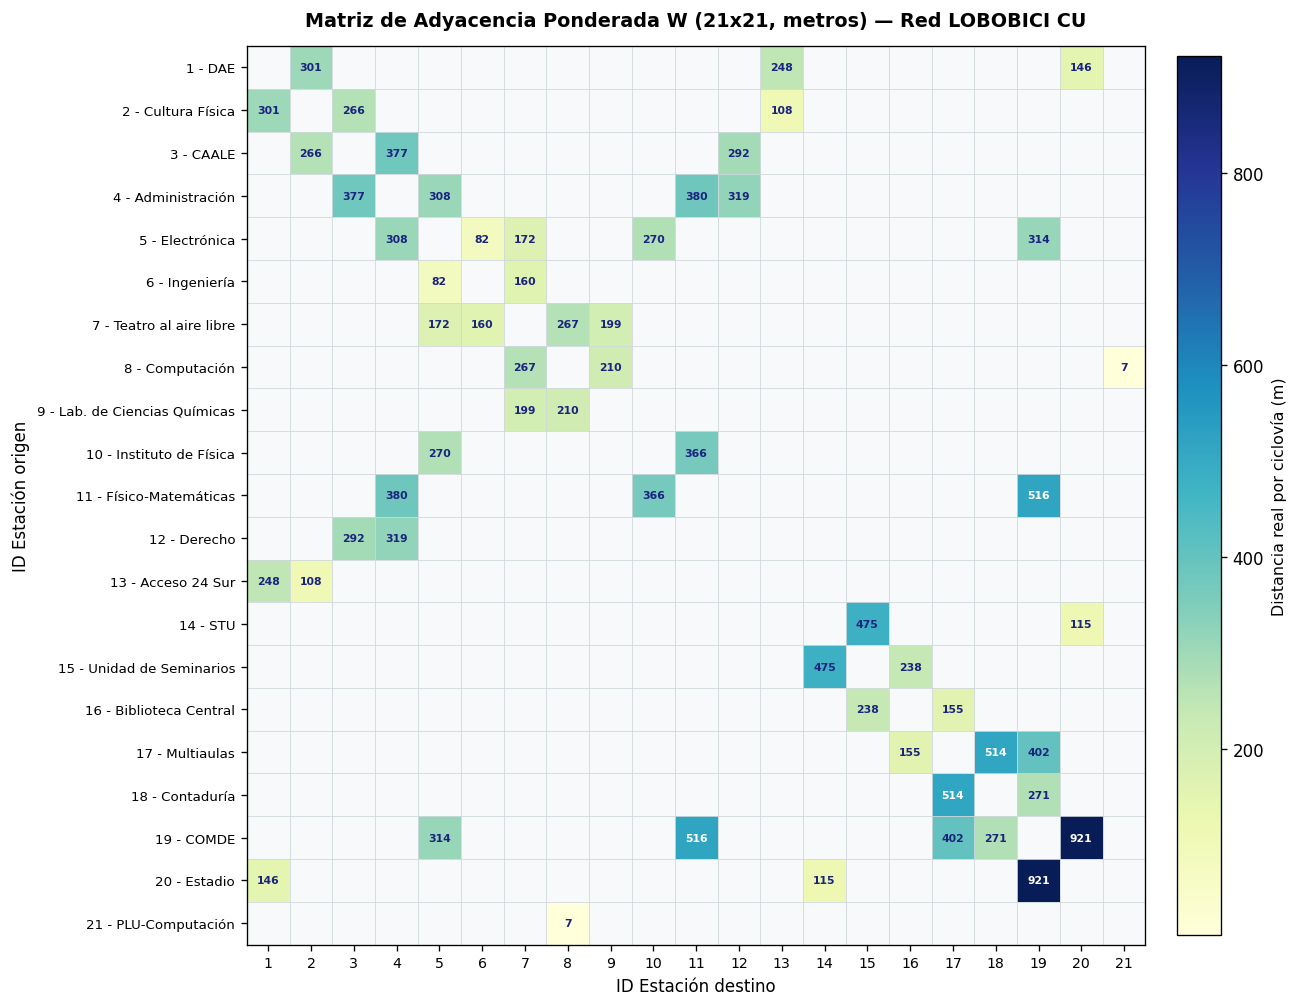

In [51]:
# MATRIZ DE ADYACENCIA PONDERADA W (|V| x |V|), 0 si no existe conexión

nodos_ord = sorted(G.nodes())

W_adj = nx.to_numpy_array(G, nodelist=nodos_ord, weight="dist_ruta_m", dtype=float)

es_simetrica = np.allclose(W_adj, W_adj.T)
diagonal_cero = np.all(np.diag(W_adj) == 0)
entradas_no_nulas = int(np.count_nonzero(W_adj))

print("=== MATRIZ DE ADYACENCIA PONDERADA W (dist_ruta_m en metros) ===")
print(f"Dimensión |V| x |V|   : {W_adj.shape[0]} x {W_adj.shape[1]}")
print(f"Simétrica (W = W^T)   : {es_simetrica} (grafo no dirigido)")
print(f"Diagonal de ceros     : {diagonal_cero} (grafo simple)")
print(f"Entradas > 0          : {entradas_no_nulas} (= 2|E| = {2 * G.number_of_edges()})")
print(f"Longitud total de red : {W_adj.sum() / 2:.1f} m\n")

# Impresión formateada (pesos redondeados a metros enteros para lectura compacta)
encabezado = "    " + " ".join(f"{nid:4d}" for nid in nodos_ord)
print(encabezado)
print("   " + "-" * (len(encabezado) - 3))
for i, nid in enumerate(nodos_ord):
    fila_str = " ".join(f"{val:4.0f}" if val > 0 else "   0" for val in W_adj[i])
    print(f"{nid:2d} |{fila_str}")

nodo_ej = nodos_ord[0]
idx_ej = nodos_ord.index(nodo_ej)
vecinos_ej = sorted(G.neighbors(nodo_ej))
print(f"\n--- Comprobación manual (ejemplo: nodo {nodo_ej} - {G.nodes[nodo_ej]['nombre']}) ---")
for v in vecinos_ej:
    j = nodos_ord.index(v)
    print(f"  W[{nodo_ej}, {v:2d}] = {W_adj[idx_ej, j]:5.1f} m  ({G.nodes[nodo_ej]['nombre']} <-> {G.nodes[v]['nombre']})")
print(f"Entradas > 0 en fila {nodo_ej} : {int(np.count_nonzero(W_adj[idx_ej]))} (coincide con deg({nodo_ej}) = {G.degree(nodo_ej)})")

# Visualización de la Matriz de Adyacencia Ponderada
fig, ax = plt.subplots(figsize=(10.5, 8.5), dpi=120)
W_vis = np.ma.masked_where(W_adj == 0, W_adj)
cmap = plt.cm.YlGnBu.copy()
cmap.set_bad(color="#F7F9FA")
im = ax.imshow(W_vis, cmap=cmap, aspect="equal")
cbar = plt.colorbar(im, ax=ax, fraction=0.042, pad=0.03)
cbar.set_label("Distancia real por ciclovía (m)", fontsize=9.5)

ax.set_xticks(range(len(nodos_ord)))
ax.set_yticks(range(len(nodos_ord)))
ax.set_xticklabels(nodos_ord, fontsize=8.5)
ax.set_yticklabels([f"{n} - {G.nodes[n]['nombre']}" for n in nodos_ord], fontsize=8)
ax.set_xlabel("ID Estación destino", fontsize=10)
ax.set_ylabel("ID Estación origen", fontsize=10)
ax.set_title(f"Matriz de Adyacencia Ponderada W ({W_adj.shape[0]}x{W_adj.shape[1]}, metros) — Red LOBOBICI CU", fontsize=11.5, fontweight="bold", pad=12)

umbral_txt = W_adj.max() * 0.55 if W_adj.max() > 0 else 1
for i in range(W_adj.shape[0]):
    for j in range(W_adj.shape[1]):
        if W_adj[i, j] > 0:
            color_txt = "white" if W_adj[i, j] >= umbral_txt else "#1A237E"
            ax.text(j, i, f"{W_adj[i, j]:.0f}", ha="center", va="center", color=color_txt, fontsize=6.5, fontweight="bold")

ax.set_xticks(np.arange(-0.5, len(nodos_ord), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(nodos_ord), 1), minor=True)
ax.grid(which="minor", color="#CFD8DC", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)
plt.tight_layout()
plt.show()

=== MATRIZ DE INCIDENCIA M (|V| x |E|) ===
Dimensión |V| x |E|          : 21 x 29
Todas las columnas suman 2   : True (cada arista conecta 2 vértices)
Suma de cada fila = grado(v) : True
Total de unos                : 58 (= 2|E| = 58)

Catálogo de aristas (columnas):
  e01 = { 1,  2} | 301.3 m | DAE <-> Cultura Física
  e02 = { 1, 13} | 247.5 m | DAE <-> Acceso 24 Sur
  e03 = { 1, 20} | 146.5 m | DAE <-> Estadio
  e04 = { 2,  3} | 265.8 m | Cultura Física <-> CAALE
  e05 = { 2, 13} | 107.9 m | Cultura Física <-> Acceso 24 Sur
  e06 = { 3,  4} | 377.4 m | CAALE <-> Administración
  e07 = { 3, 12} | 292.2 m | CAALE <-> Derecho
  e08 = { 4,  5} | 308.3 m | Administración <-> Electrónica
  e09 = { 4, 11} | 380.2 m | Administración <-> Físico-Matemáticas
  e10 = { 4, 12} | 319.0 m | Administración <-> Derecho
  e11 = { 5,  6} |  81.5 m | Electrónica <-> Ingeniería
  e12 = { 5,  7} | 172.2 m | Electrónica <-> Teatro al aire libre
  e13 = { 5, 10} | 269.7 m | Electrónica <-> Instituto de Físi

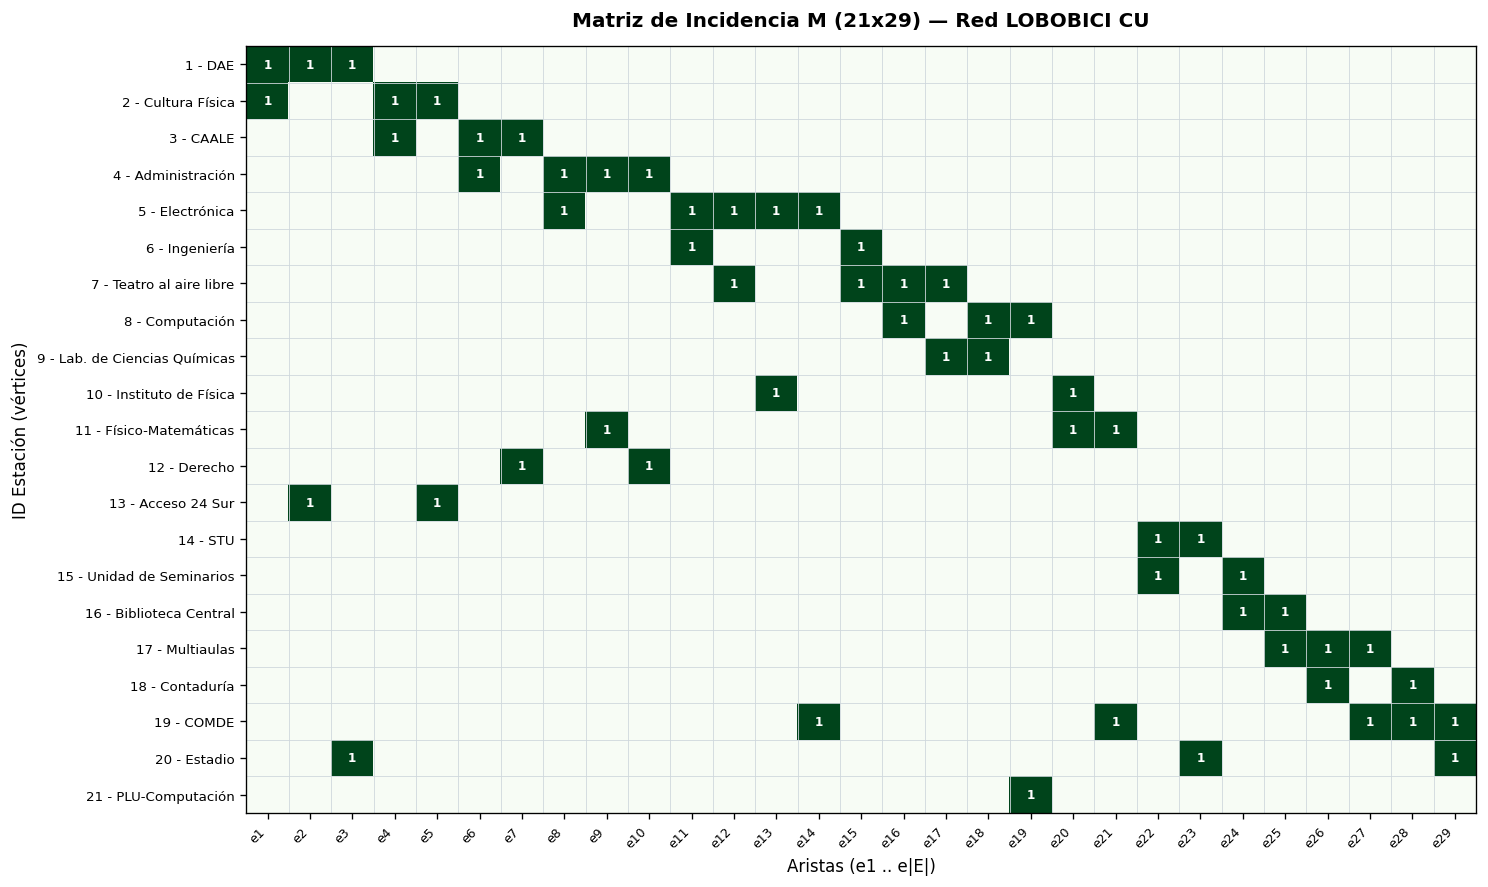

In [52]:
# Matriz de incidencia M (nodos x aristas), 1 si el vértice pertenece a la arista
nodos_ord = sorted(G.nodes())
aristas_ord = sorted([tuple(sorted((u, v))) for u, v in G.edges()])

M = nx.incidence_matrix(G, nodelist=nodos_ord, edgelist=aristas_ord, oriented=False).toarray().astype(int)

sumas_col = M.sum(axis=0)
sumas_fila = M.sum(axis=1)
grados_G = np.array([G.degree(n) for n in nodos_ord])

print("=== MATRIZ DE INCIDENCIA M (|V| x |E|) ===")
print(f"Dimensión |V| x |E|          : {M.shape[0]} x {M.shape[1]}")
print(f"Todas las columnas suman 2   : {bool(np.all(sumas_col == 2))} (cada arista conecta 2 vértices)")
print(f"Suma de cada fila = grado(v) : {bool(np.array_equal(sumas_fila, grados_G))}")
print(f"Total de unos                : {int(M.sum())} (= 2|E| = {2 * len(aristas_ord)})\n")

# Catálogo de aristas e1..e|E| con su peso real para lectura y comprobación manual
print("Catálogo de aristas (columnas):")
for k, (u, v) in enumerate(aristas_ord, start=1):
    dist = G[u][v]["dist_ruta_m"]
    print(f"  e{k:02d} = {{{u:2d}, {v:2d}}} | {dist:5.1f} m | {G.nodes[u]['nombre']} <-> {G.nodes[v]['nombre']}")

# Impresión formateada de la matriz M
print("\nMatriz M (filas = ID estación, columnas = e1..e|E|):")
encabezado_M = "    " + " ".join(f"{k:2d}" for k in range(1, len(aristas_ord) + 1))
print(encabezado_M)
print("   " + "-" * (len(encabezado_M) - 3))
for i, nid in enumerate(nodos_ord):
    fila_str = " ".join(f"{val:2d}" for val in M[i])
    print(f"{nid:2d} |{fila_str}")

# Referencia rápida para comprobación manual en el reporte técnico (ej. e01)
u0, v0 = aristas_ord[0]
filas_con_1 = [nodos_ord[i] for i in range(len(nodos_ord)) if M[i, 0] == 1]
print(f"\n--- Comprobación manual (ejemplo: columna e01 = {{{u0}, {v0}}}) ---")
print(f"Vértices con 1 en columna e01 : {filas_con_1} ({G.nodes[u0]['nombre']} y {G.nodes[v0]['nombre']})")
print(f"Suma de la columna e01        : {int(M[:, 0].sum())}")

# Visualización de la Matriz de Incidencia
fig, ax = plt.subplots(figsize=(12.5, 7.5), dpi=120)
ax.imshow(M, cmap="Greens", aspect="auto")
ax.set_xticks(range(len(aristas_ord)))
ax.set_yticks(range(len(nodos_ord)))
ax.set_xticklabels([f"e{k}" for k in range(1, len(aristas_ord) + 1)], fontsize=7.5, rotation=45, ha="right")
ax.set_yticklabels([f"{n} - {G.nodes[n]['nombre']}" for n in nodos_ord], fontsize=8)
ax.set_xlabel("Aristas (e1 .. e|E|)", fontsize=10)
ax.set_ylabel("ID Estación (vértices)", fontsize=10)
ax.set_title(f"Matriz de Incidencia M ({M.shape[0]}x{M.shape[1]}) — Red LOBOBICI CU", fontsize=12, fontweight="bold", pad=12)

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M[i, j] == 1:
            ax.text(j, i, "1", ha="center", va="center", color="white", fontsize=7.2, fontweight="bold")

ax.set_xticks(np.arange(-0.5, len(aristas_ord), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(nodos_ord), 1), minor=True)
ax.grid(which="minor", color="#CFD8DC", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)
plt.tight_layout()
plt.show()

### Sección 3: Caminos, Ciclos y Recorridos (Euler y Hamilton)

=== EVALUACIÓN EULERIANA DE G ===
Vértices de grado par   (11): [4, 6, 7, 9, 10, 12, 13, 14, 15, 16, 18]
Vértices de grado impar (10): [(1, 'DAE', 3), (2, 'Cultura Física', 3), (3, 'CAALE', 3), (5, 'Electrónica', 5), (8, 'Computación', 3), (11, 'Físico-Matemáticas', 3), (17, 'Multiaulas', 3), (19, 'COMDE', 5), (20, 'Estadio', 3), (21, 'PLU-Computación', 1)]
¿Posee Ciclo de Euler?  : False (requiere 0 nodos impares)
¿Posee Camino de Euler? : False (requiere 0 o 2 nodos impares)

--- Emparejamiento óptimo de vértices impares y aristas añadidas ---
  Par ( 1-DAE <-> 20-Estadio) | +146.5 m | ruta: [1, 20]
  Par ( 2-Cultura Física <->  3-CAALE) | +265.8 m | ruta: [2, 3]
  Par ( 5-Electrónica <-> 11-Físico-Matemáticas) | +635.8 m | ruta: [5, 10, 11]
  Par ( 8-Computación <-> 21-PLU-Computación) | +  7.1 m | ruta: [8, 21]
  Par (17-Multiaulas <-> 19-COMDE) | +401.9 m | ruta: [17, 19]

Detalle de aristas duplicadas (añadidas a G_eul):
  +1: { 1, 20} (DAE <-> Estadio) — 146.5 m
  +2: { 2,  3} (

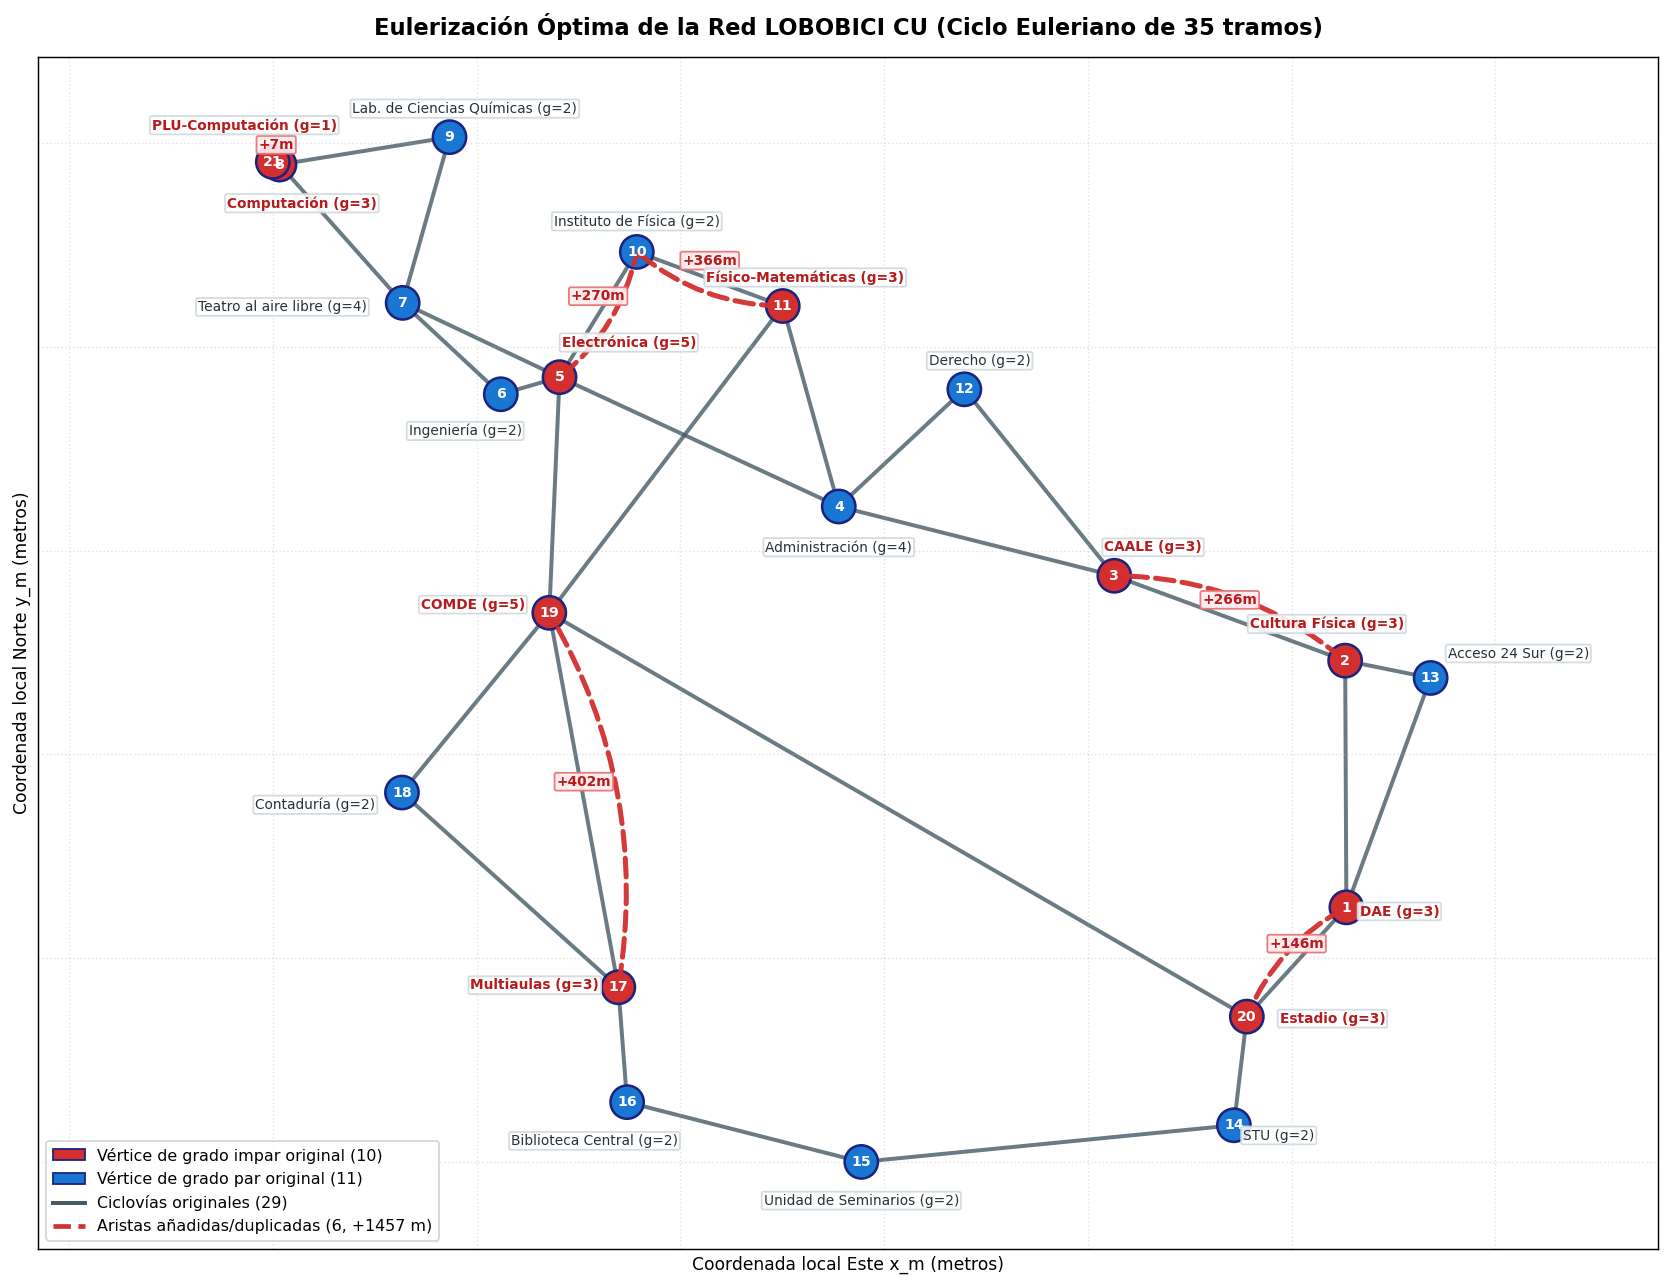

In [53]:
# Análisis euleriano y eulerización por distancia mínima
# Si en la demo se desconecta G, se trabaja sobre la componente conexa principal
if nx.is_connected(G):
    G_base = G
else:
    comp_mayor = max(nx.connected_components(G), key=len)
    G_base = G.subgraph(comp_mayor).copy()
    print(f"[Aviso] G no es conexo; se analiza su componente principal ({len(comp_mayor)} nodos).\n")

grados_eul = dict(G_base.degree())
impares = sorted([n for n, deg in grados_eul.items() if deg % 2 == 1])
pares = sorted([n for n, deg in grados_eul.items() if deg % 2 == 0])

tiene_ciclo_euler = nx.is_eulerian(G_base)
tiene_camino_euler = nx.has_eulerian_path(G_base)

print("=== EVALUACIÓN EULERIANA DE G ===")
print(f"Vértices de grado par   ({len(pares):2d}): {pares}")
print(f"Vértices de grado impar ({len(impares):2d}): {[(n, G_base.nodes[n]['nombre'], grados_eul[n]) for n in impares]}")
print(f"¿Posee Ciclo de Euler?  : {tiene_ciclo_euler} (requiere 0 nodos impares)")
print(f"¿Posee Camino de Euler? : {tiene_camino_euler} (requiere 0 o 2 nodos impares)")

# Eulerización emparejando vértices impares por menor distancia
G_eul = nx.MultiGraph(G_base)
aristas_anadidas = []
dist_extra = 0.0

if not tiene_ciclo_euler:
    # Grafo auxiliar completo entre vértices impares ponderado por distancia más corta en G
    K_impares = nx.Graph()
    for i, u in enumerate(impares):
        dists = nx.single_source_dijkstra_path_length(G_base, u, weight="dist_ruta_m")
        for v in impares[i + 1:]:
            K_impares.add_edge(u, v, weight=dists[v])

    emparejamiento = sorted([tuple(sorted(par)) for par in nx.min_weight_matching(K_impares, weight="weight")])

    print("\n--- Emparejamiento óptimo de vértices impares y aristas añadidas ---")
    for u, v in emparejamiento:
        ruta = nx.shortest_path(G_base, u, v, weight="dist_ruta_m")
        dist_par = nx.shortest_path_length(G_base, u, v, weight="dist_ruta_m")
        print(f"  Par ({u:2d}-{G_base.nodes[u]['nombre']} <-> {v:2d}-{G_base.nodes[v]['nombre']}) | +{dist_par:5.1f} m | ruta: {ruta}")
        for a, b in zip(ruta[:-1], ruta[1:]):
            w = G_base[a][b]["dist_ruta_m"]
            G_eul.add_edge(a, b, dist_ruta_m=w, anadida=True)
            aristas_anadidas.append((a, b, w))
            dist_extra += w

    print("\nDetalle de aristas duplicadas (añadidas a G_eul):")
    for idx_a, (a, b, w) in enumerate(aristas_anadidas, start=1):
        print(f"  +{idx_a}: {{{a:2d}, {b:2d}}} ({G_base.nodes[a]['nombre']} <-> {G_base.nodes[b]['nombre']}) — {w:.1f} m")

dist_original = sum(d["dist_ruta_m"] for _, _, d in G_base.edges(data=True))
nodo_inicio_eul = 20 if 20 in G_eul else sorted(G_eul.nodes())[0]
circuito_euler = list(nx.eulerian_circuit(G_eul, source=nodo_inicio_eul))

print("\n=== VALIDACIÓN TRAS EULERIZACIÓN (G_eul) ===")
print(f"nx.is_eulerian(G_eul)     : {nx.is_eulerian(G_eul)} (todos los grados ahora son pares)")
print(f"Aristas originales        : {G_base.number_of_edges()} ({dist_original:.1f} m)")
print(f"Aristas añadidas          : {len(aristas_anadidas)} (+{dist_extra:.1f} m, +{100*dist_extra/dist_original:.1f}%)")
print(f"Total tramos del ciclo    : {len(circuito_euler)} ({dist_original + dist_extra:.1f} m)")
secuencia_eul = [circuito_euler[0][0]] + [v for _, v in circuito_euler]
print(f"Circuito Euleriano (IDs)  : {' -> '.join(map(str, secuencia_eul))}")

# Gráfica de la eulerización (originales vs duplicadas)
fig, ax = plt.subplots(figsize=(13.5, 10), dpi=130)

# Ciclovías originales
nx.draw_networkx_edges(G_base, pos, ax=ax, edge_color="#455A64", width=2.2, alpha=0.8)

# Aristas duplicadas resaltadas con ligera curvatura roja punteada
for a, b, w in aristas_anadidas:
    x1, y1 = pos[a]
    x2, y2 = pos[b]
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-", color="#D32F2F", lw=2.8, ls="--",
            connectionstyle="arc3,rad=0.18", alpha=0.95,
        ),
    )
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    ax.text(
        mx, my + 18, f"+{w:.0f}m",
        fontsize=7.6, fontweight="bold", color="#B71C1C", ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.14", facecolor="#FFEBEE", edgecolor="#E57373", alpha=0.92),
    )

# Nodos coloreados según su paridad original en G
colores_eul = ["#D32F2F" if n in impares else "#1976D2" for n in G_base.nodes()]
nx.draw_networkx_nodes(G_base, pos, ax=ax, node_color=colores_eul, edgecolors="#1A237E", linewidths=1.4, node_size=340)
nx.draw_networkx_labels(G_base, pos, ax=ax, font_size=7.8, font_weight="bold", font_color="white")

for nid in G_base.nodes():
    x, y = pos[nid]
    dx, dy = label_offsets.get(nid, (18, 18))
    ax.text(
        x + dx, y + dy, f"{G_base.nodes[nid]['nombre']} (g={grados_eul[nid]})",
        fontsize=7.6, fontweight="semibold" if nid in impares else "normal",
        color="#B71C1C" if nid in impares else "#263238",
        ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.14", facecolor="white", edgecolor="#CFD8DC", alpha=0.88),
    )

leyenda_eul = [
    mpatches.Patch(facecolor="#D32F2F", edgecolor="#1A237E", label=f"Vértice de grado impar original ({len(impares)})"),
    mpatches.Patch(facecolor="#1976D2", edgecolor="#1A237E", label=f"Vértice de grado par original ({len(pares)})"),
    mlines.Line2D([], [], color="#455A64", linewidth=2.2, label=f"Ciclovías originales ({G_base.number_of_edges()})"),
    mlines.Line2D([], [], color="#D32F2F", linewidth=2.6, linestyle="--", label=f"Aristas añadidas/duplicadas ({len(aristas_anadidas)}, +{dist_extra:.0f} m)"),
]
ax.legend(handles=leyenda_eul, loc="lower left", frameon=True, fontsize=8.8)
ax.set_title(f"Eulerización Óptima de la Red LOBOBICI CU (Ciclo Euleriano de {len(circuito_euler)} tramos)", fontsize=12.5, fontweight="bold", pad=12)
ax.set_xlabel("Coordenada local Este x_m (metros)", fontsize=9.5)
ax.set_ylabel("Coordenada local Norte y_m (metros)", fontsize=9.5)
ax.set_aspect("equal")
ax.set_xlim(-230, 1360)
ax.set_ylim(-85, 1085)
ax.grid(True, linestyle=":", alpha=0.35)
plt.tight_layout()
plt.show()

=== A) BÚSQUEDA EXACTA — SUBGRAFO DE 8 NODOS (CIRCUITO CENTRO-ESTE) ===
Nodos de H_sub8 (8) : ['1-DAE', '2-Cultura Física', '3-CAALE', '4-Administración', '11-Físico-Matemáticas', '13-Acceso 24 Sur', '19-COMDE', '20-Estadio']
Aristas en H_sub8    : 9
Ciclo Hamiltoniano   : 1 -> 13 -> 2 -> 3 -> 4 -> 11 -> 19 -> 20 -> 1
Distancia total      : 2962.4 m
Estados explorados   : 22 (peor caso teórico (n-1)! = 5040)

=== B) ANÁLISIS HAMILTONIANO — RED COMPLETA G ===
¿Ciclo Hamiltoniano en G? : False (existen nodos con grado < 2: [(21, 'PLU-Computación', 1)])
¿Camino Hamiltoniano en G?: True (visita las 21 estaciones sin repetir)
Camino más corto hallado  : 21 -> 8 -> 9 -> 7 -> 6 -> 5 -> 10 -> 11 -> 4 -> 12 -> 3 -> 2 -> 13 -> 1 -> 20 -> 14 -> 15 -> 16 -> 17 -> 19 -> 18
Inicio -> Fin             : 21-PLU-Computación -> 18-Contaduría
Distancia total           : 4707.6 m | Estados explorados: 1818


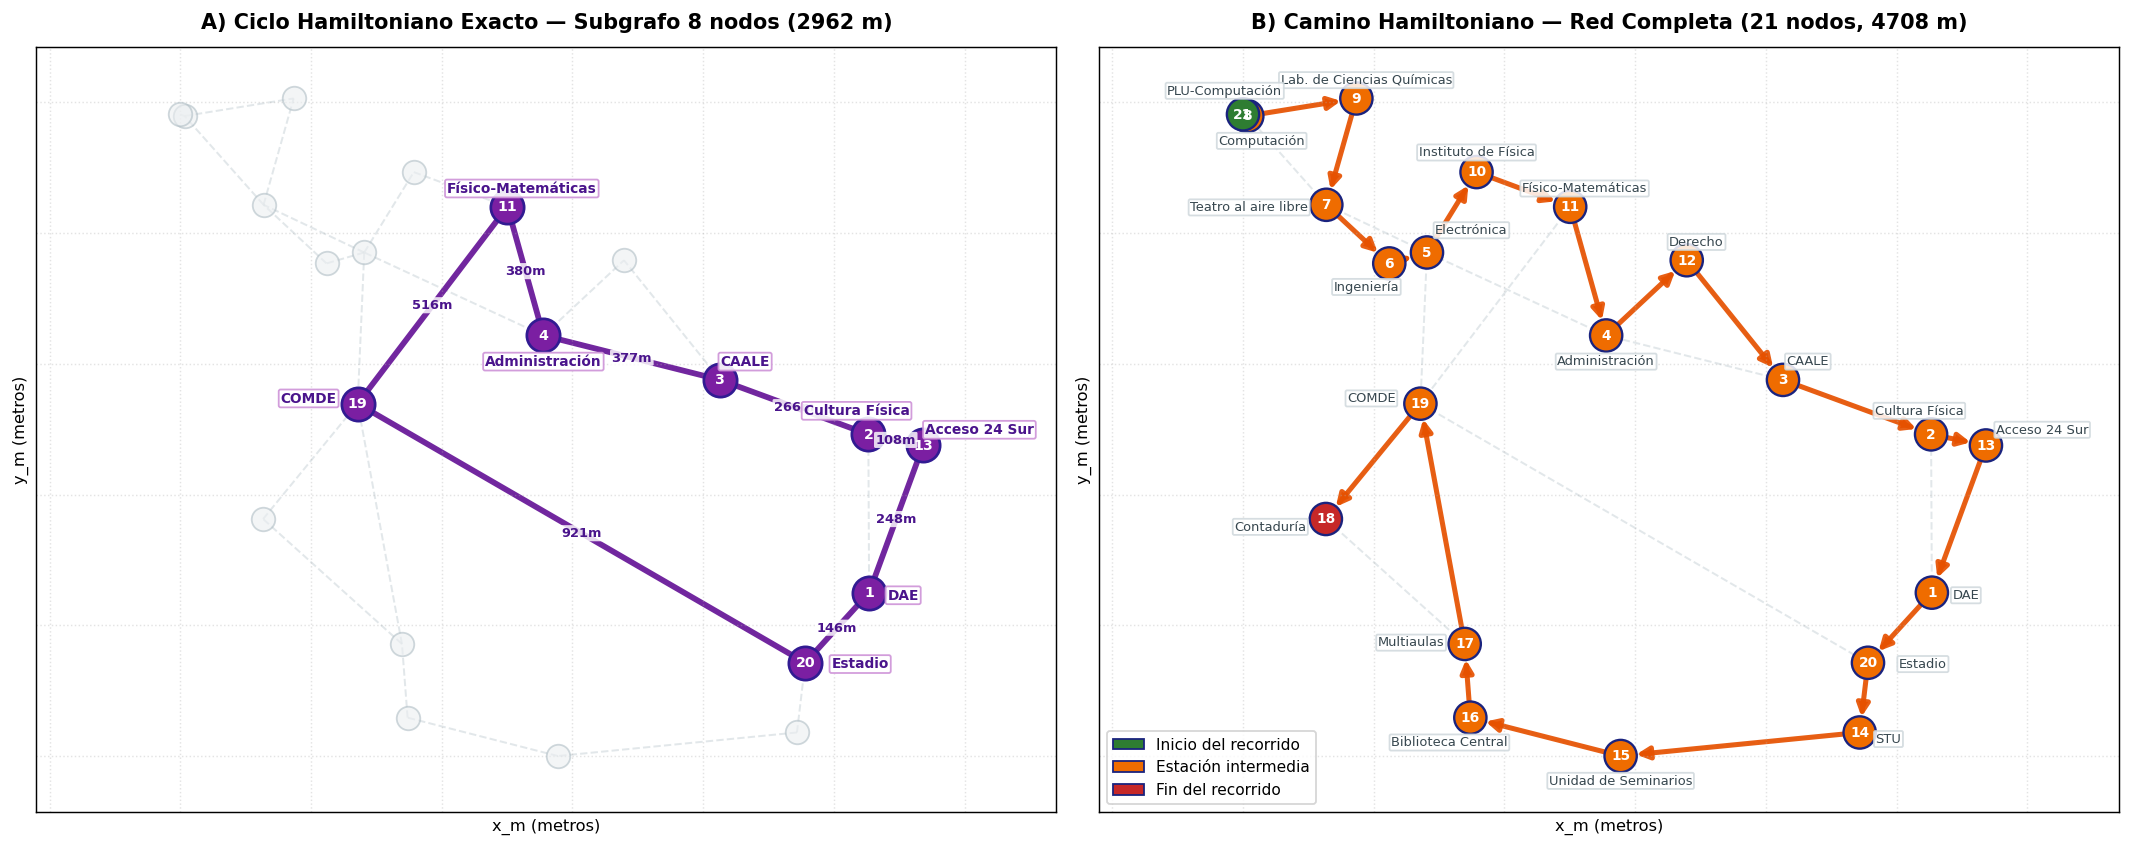

In [54]:
# ANÁLISIS HAMILTONIANO (BÚSQUEDA EXACTA + HEURÍSTICA)

import math

def buscar_ciclo_hamilton_exacto(H):
    nodos = sorted(H.nodes())
    n = len(nodos)
    if n < 3:
        return None, 0.0, 0
    inicio = nodos[0]
    mejor_ciclo = None
    mejor_dist = float("inf")
    estados = 0
    camino = [inicio]
    visitados = {inicio}

    def backtrack(u, dist_acum):
        nonlocal mejor_ciclo, mejor_dist, estados
        estados += 1
        if dist_acum >= mejor_dist:
            return
        if len(camino) == n:
            if H.has_edge(u, inicio):
                total = dist_acum + H[u][inicio]["dist_ruta_m"]
                if total < mejor_dist:
                    mejor_dist = total
                    mejor_ciclo = camino + [inicio]
            return
        for v in sorted(H.neighbors(u)):
            if v not in visitados:
                visitados.add(v)
                camino.append(v)
                backtrack(v, dist_acum + H[u][v]["dist_ruta_m"])
                camino.pop()
                visitados.remove(v)

    backtrack(inicio, 0.0)
    return mejor_ciclo, (mejor_dist if mejor_ciclo else 0.0), estados


def buscar_camino_hamilton(H, max_estados=100000):
    """Backtracking guiado por grado mínimo (heurística de Warnsdorff) para hallar camino Hamiltoniano."""
    nodos = sorted(H.nodes())
    n = len(nodos)
    grado_uno = [u for u in nodos if H.degree(u) == 1]
    if len(grado_uno) > 2:
        return None, 0.0, 0
    inicios = grado_uno[:1] if grado_uno else sorted(nodos, key=lambda x: H.degree(x))
    adj = {u: sorted(H.neighbors(u), key=lambda x: (H.degree(x), H[u][x]["dist_ruta_m"])) for u in nodos}

    mejor_camino = None
    mejor_dist = float("inf")
    estados = 0

    for s in inicios:
        camino = [s]
        visitados = {s}

        def bt(u, dist_acum):
            nonlocal mejor_camino, mejor_dist, estados
            estados += 1
            if estados > max_estados or dist_acum >= mejor_dist:
                return
            if len(camino) == n:
                mejor_dist = dist_acum
                mejor_camino = list(camino)
                return
            for v in adj[u]:
                if v not in visitados:
                    visitados.add(v)
                    camino.append(v)
                    bt(v, dist_acum + H[u][v]["dist_ruta_m"])
                    camino.pop()
                    visitados.remove(v)

        bt(s, 0.0)
        if mejor_camino and grado_uno:
            break

    return mejor_camino, (mejor_dist if mejor_camino else 0.0), estados


# A) Búsqueda exacta en subgrafo de 8 nodos (Circuito Centro-Este)
nodos_sub8 = [n for n in [1, 2, 3, 4, 11, 13, 19, 20] if n in G]
H_sub8 = G.subgraph(nodos_sub8).copy()
ciclo_h8, dist_c8, estados_c8 = buscar_ciclo_hamilton_exacto(H_sub8)

print("=== A) BÚSQUEDA EXACTA — SUBGRAFO DE 8 NODOS (CIRCUITO CENTRO-ESTE) ===")
print(f"Nodos de H_sub8 ({H_sub8.number_of_nodes()}) : {[f'{n}-{G.nodes[n]["nombre"]}' for n in sorted(H_sub8.nodes())]}")
print(f"Aristas en H_sub8    : {H_sub8.number_of_edges()}")
if ciclo_h8:
    print(f"Ciclo Hamiltoniano   : {' -> '.join(map(str, ciclo_h8))}")
    print(f"Distancia total      : {dist_c8:.1f} m")
else:
    print("Ciclo Hamiltoniano   : No existe en este subgrafo")
print(f"Estados explorados   : {estados_c8} (peor caso teórico (n-1)! = {math.factorial(max(len(nodos_sub8) - 1, 1))})")

# B) Análisis hamiltoniano en la red completa G
nodos_deg_menor_2 = [(n, G.nodes[n]["nombre"], G.degree(n)) for n in sorted(G.nodes()) if G.degree(n) < 2]
camino_h_full, dist_hf, estados_hf = buscar_camino_hamilton(G)

print("\n=== B) ANÁLISIS HAMILTONIANO — RED COMPLETA G ===")
if nodos_deg_menor_2:
    print(f"¿Ciclo Hamiltoniano en G? : False (existen nodos con grado < 2: {nodos_deg_menor_2})")
else:
    print("¿Ciclo Hamiltoniano en G? : Requiere búsqueda completa (todos los grados >= 2)")

if camino_h_full:
    print(f"¿Camino Hamiltoniano en G?: True (visita las {len(camino_h_full)} estaciones sin repetir)")
    print(f"Camino más corto hallado  : {' -> '.join(map(str, camino_h_full))}")
    print(f"Inicio -> Fin             : {camino_h_full[0]}-{G.nodes[camino_h_full[0]]['nombre']} -> {camino_h_full[-1]}-{G.nodes[camino_h_full[-1]]['nombre']}")
    print(f"Distancia total           : {dist_hf:.1f} m | Estados explorados: {estados_hf}")
else:
    print(f"¿Camino Hamiltoniano en G?: False (no encontrado en {estados_hf} estados)")

fig, axes = plt.subplots(1, 2, figsize=(16.5, 7.8), dpi=130)

ax0 = axes[0]
nx.draw_networkx_edges(G, pos, ax=ax0, edge_color="#CFD8DC", width=1.1, style="--", alpha=0.6)
nx.draw_networkx_nodes(G, pos, ax=ax0, node_color="#ECEFF1", edgecolors="#B0BEC5", node_size=170, alpha=0.6)
if ciclo_h8:
    aristas_c8 = list(zip(ciclo_h8[:-1], ciclo_h8[1:]))
    nx.draw_networkx_edges(H_sub8, pos, edgelist=aristas_c8, ax=ax0, edge_color="#6A1B9A", width=3.2, alpha=0.95)
    for u, v in aristas_c8:
        mx, my = (pos[u][0] + pos[v][0]) / 2, (pos[u][1] + pos[v][1]) / 2
        ax0.text(mx, my, f"{G[u][v]['dist_ruta_m']:.0f}m", fontsize=7.2, color="#4A148C", fontweight="bold",
                 ha="center", va="center", bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none", alpha=0.82))
nx.draw_networkx_nodes(H_sub8, pos, ax=ax0, node_color="#7B1FA2", edgecolors="#311B92", linewidths=1.5, node_size=340)
nx.draw_networkx_labels(H_sub8, pos, ax=ax0, font_size=7.8, font_weight="bold", font_color="white")
for nid in H_sub8.nodes():
    x, y = pos[nid]
    dx, dy = label_offsets.get(nid, (18, 18))
    ax0.text(x + dx, y + dy, G.nodes[nid]["nombre"], fontsize=7.6, fontweight="semibold", color="#4A148C",
             ha="center", va="center", bbox=dict(boxstyle="round,pad=0.14", facecolor="white", edgecolor="#CE93D8", alpha=0.9))
ax0.set_title(f"A) Ciclo Hamiltoniano Exacto — Subgrafo {len(nodos_sub8)} nodos ({dist_c8:.0f} m)", fontsize=11.5, fontweight="bold", pad=10)
ax0.set_xlabel("x_m (metros)", fontsize=9)
ax0.set_ylabel("y_m (metros)", fontsize=9)
ax0.set_aspect("equal")
ax0.set_xlim(-220, 1340)
ax0.set_ylim(-85, 1085)
ax0.grid(True, linestyle=":", alpha=0.35)

# Panel 2: Camino Hamiltoniano en G completo (21 nodos)
ax1 = axes[1]
nx.draw_networkx_edges(G, pos, ax=ax1, edge_color="#CFD8DC", width=1.1, style="--", alpha=0.6)
if camino_h_full:
    aristas_hf = list(zip(camino_h_full[:-1], camino_h_full[1:]))
    G_dir_h = nx.DiGraph()
    G_dir_h.add_edges_from(aristas_hf)
    nx.draw_networkx_edges(
        G_dir_h, pos, edgelist=aristas_hf, ax=ax1,
        edge_color="#E65100", width=2.8, arrows=True, arrowsize=14, arrowstyle="-|>", alpha=0.92,
    )
    colores_hf = [
        "#2E7D32" if n == camino_h_full[0] else ("#C62828" if n == camino_h_full[-1] else "#EF6C00")
        for n in G.nodes()
    ]
else:
    colores_hf = "#90A4AE"
nx.draw_networkx_nodes(G, pos, ax=ax1, node_color=colores_hf, edgecolors="#1A237E", linewidths=1.3, node_size=320)
nx.draw_networkx_labels(G, pos, ax=ax1, font_size=7.6, font_weight="bold", font_color="white")
for nid in G.nodes():
    x, y = pos[nid]
    dx, dy = label_offsets.get(nid, (18, 18))
    ax1.text(x + dx, y + dy, G.nodes[nid]["nombre"], fontsize=7.2, color="#37474F",
             ha="center", va="center", bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="#CFD8DC", alpha=0.85))
leyenda_h = [
    mpatches.Patch(facecolor="#2E7D32", edgecolor="#1A237E", label="Inicio del recorrido"),
    mpatches.Patch(facecolor="#EF6C00", edgecolor="#1A237E", label="Estación intermedia"),
    mpatches.Patch(facecolor="#C62828", edgecolor="#1A237E", label="Fin del recorrido"),
]
ax1.legend(handles=leyenda_h, loc="lower left", frameon=True, fontsize=8.5)
ax1.set_title(f"B) Camino Hamiltoniano — Red Completa ({G.number_of_nodes()} nodos, {dist_hf:.0f} m)", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("x_m (metros)", fontsize=9)
ax1.set_ylabel("y_m (metros)", fontsize=9)
ax1.set_aspect("equal")
ax1.set_xlim(-220, 1340)
ax1.set_ylim(-85, 1085)
ax1.grid(True, linestyle=":", alpha=0.35)

plt.tight_layout()
plt.show()

### Sección 4: Isomorfismo de Grafos

=== BÚSQUEDA DINÁMICA DE SUBGRAFOS COMPARABLES EN G (K=5 nodos) ===
Sectores locales únicos hallados : 15
Pares disjuntos con igual |V|,|E|: 28 (9 isomorfos, 19 no isomorfos)

=== CASO 1 — PAR ISOMORFO (|V|=5, |E|=5) ===
  Subgrafo A (entorno  1-DAE): [1, 2, 13, 14, 20]
  Subgrafo B (entorno 10-Instituto de Física): [5, 6, 7, 10, 11]
  nx.is_isomorphic(A, B) : True
  Invariantes A          : conexo=True (comp=1), grados=[3, 2, 2, 2, 1], ciclos=[3]
  Invariantes B          : conexo=True (comp=1), grados=[3, 2, 2, 2, 1], ciclos=[3]
  Biyección f: V(A)->V(B): 1(DAE) <-> 5(Electrónica), 2(Cultura Física) <-> 6(Ingeniería), 13(Acceso 24 Sur) <-> 7(Teatro al aire libre), 14(STU) <-> 11(Físico-Matemáticas), 20(Estadio) <-> 10(Instituto de Física)

=== CASO 2 — PAR NO ISOMORFO (|V|=5, |E|=5) ===
  Subgrafo A (entorno  1-DAE): [1, 2, 13, 14, 20]
  Subgrafo B (entorno  4-Administración): [3, 4, 5, 11, 12]
  nx.is_isomorphic(A, B) : False
  Invariantes A          : conexo=True (comp=1), grados=[3

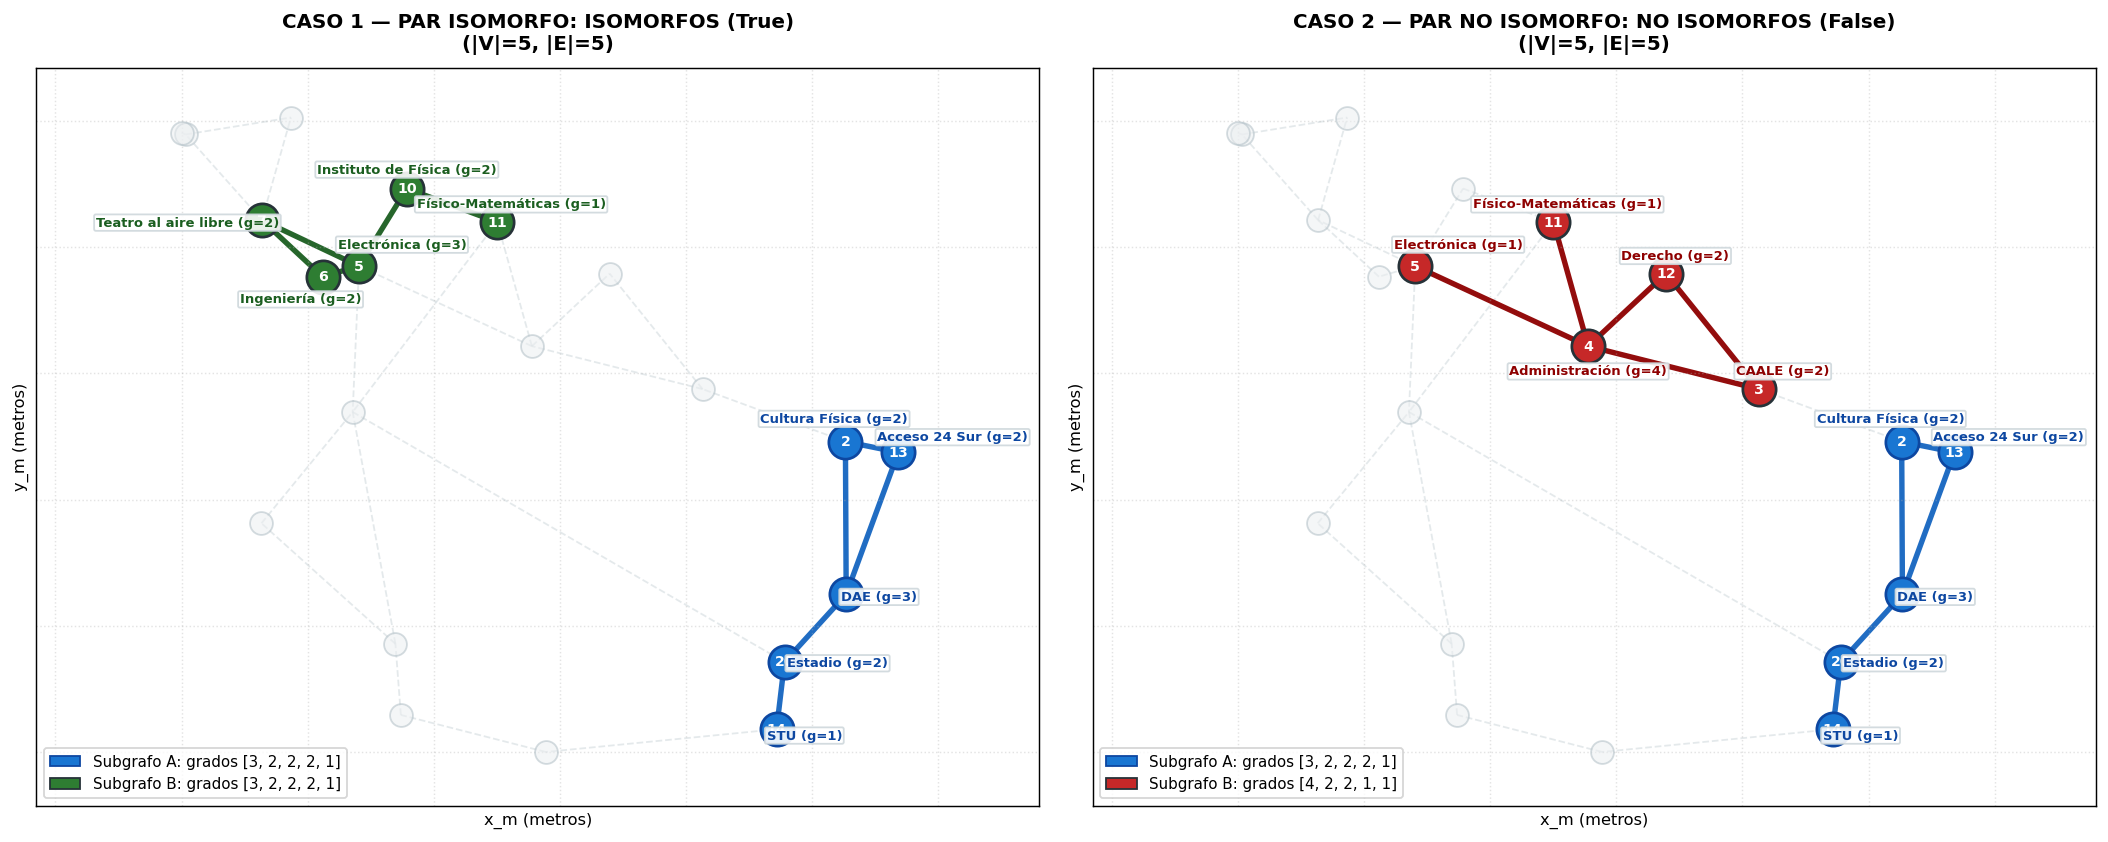

In [55]:
# Isomorfismo de grafos (búsqueda dinámica de sectores locales en G)
from collections import deque
from networkx.algorithms import isomorphism

K_NODOS = 5  # Tamaño de los sectores locales a comparar (modificable en demo)

def vecindario_bfs_k(grafo, origen, k):
    """Construye dinámicamente un subgrafo local conexo de k nodos desde 'origen' priorizando menor distancia."""
    visitados = [origen]
    vset = {origen}
    cola = deque([origen])
    while cola and len(visitados) < k:
        u = cola.popleft()
        vecinos = sorted(grafo.neighbors(u), key=lambda x: (grafo[u][x]["dist_ruta_m"], x))
        for v in vecinos:
            if v not in vset:
                vset.add(v)
                visitados.append(v)
                cola.append(v)
                if len(visitados) == k:
                    break
    return frozenset(visitados) if len(visitados) == k else None

def invariantes(H):
    """Calcula invariantes estructurales clave para demostrar o refutar isomorfismo."""
    return {
        "nodos": H.number_of_nodes(),
        "aristas": H.number_of_edges(),
        "conexo": nx.is_connected(H),
        "componentes": nx.number_connected_components(H),
        "secuencia_grados": sorted([d for _, d in H.degree()], reverse=True),
        "longitudes_ciclos": sorted([len(c) for c in nx.cycle_basis(H)]),
    }

# 1. Descubrimiento dinámico de todos los sectores locales conexos de K_NODOS en G
sectores = {}
for nodo in sorted(G.nodes()):
    conj = vecindario_bfs_k(G, nodo, K_NODOS)
    if conj and conj not in sectores:
        sectores[conj] = (nodo, G.subgraph(conj).copy())

# 2. Emparejar sectores disjuntos con exactamente igual |V| y |E|
pares_iso = []
pares_no_iso = []
lista_sectores = list(sectores.items())

for i in range(len(lista_sectores)):
    for j in range(i + 1, len(lista_sectores)):
        s1, (o1, H1) = lista_sectores[i]
        s2, (o2, H2) = lista_sectores[j]
        if s1.isdisjoint(s2) and H1.number_of_edges() == H2.number_of_edges():
            gm = isomorphism.GraphMatcher(H1, H2)
            es_iso = gm.is_isomorphic()
            biyeccion = dict(gm.mapping) if es_iso else None
            registro = (H1.number_of_edges(), o1, o2, H1, H2, es_iso, biyeccion)
            (pares_iso if es_iso else pares_no_iso).append(registro)

# Orden determinista: priorizar subgrafos más densos (mayor |E|) y menor ID de origen
pares_iso.sort(key=lambda x: (-x[0], x[1], x[2]))
pares_no_iso.sort(key=lambda x: (-x[0], x[1], x[2]))

print(f"=== BÚSQUEDA DINÁMICA DE SUBGRAFOS COMPARABLES EN G (K={K_NODOS} nodos) ===")
print(f"Sectores locales únicos hallados : {len(sectores)}")
print(f"Pares disjuntos con igual |V|,|E|: {len(pares_iso) + len(pares_no_iso)} ({len(pares_iso)} isomorfos, {len(pares_no_iso)} no isomorfos)\n")

casos = []
if pares_iso:
    casos.append(("CASO 1 — PAR ISOMORFO", pares_iso[0]))
if pares_no_iso:
    casos.append(("CASO 2 — PAR NO ISOMORFO", pares_no_iso[0]))

for titulo_caso, (num_e, o1, o2, H1, H2, es_iso, biyeccion) in casos:
    inv1, inv2 = invariantes(H1), invariantes(H2)
    print(f"=== {titulo_caso} (|V|={K_NODOS}, |E|={num_e}) ===")
    print(f"  Subgrafo A (entorno {o1:2d}-{G.nodes[o1]['nombre']}): {sorted(H1.nodes())}")
    print(f"  Subgrafo B (entorno {o2:2d}-{G.nodes[o2]['nombre']}): {sorted(H2.nodes())}")
    print(f"  nx.is_isomorphic(A, B) : {es_iso}")
    print(f"  Invariantes A          : conexo={inv1['conexo']} (comp={inv1['componentes']}), grados={inv1['secuencia_grados']}, ciclos={inv1['longitudes_ciclos']}")
    print(f"  Invariantes B          : conexo={inv2['conexo']} (comp={inv2['componentes']}), grados={inv2['secuencia_grados']}, ciclos={inv2['longitudes_ciclos']}")
    if es_iso and biyeccion:
        mapeo_txt = ", ".join(f"{u}({G.nodes[u]['nombre']}) <-> {v}({G.nodes[v]['nombre']})" for u, v in sorted(biyeccion.items()))
        print(f"  Biyección f: V(A)->V(B): {mapeo_txt}")
    else:
        diffs = []
        if inv1["secuencia_grados"] != inv2["secuencia_grados"]:
            diffs.append("secuencia de grados distinta")
        if inv1["componentes"] != inv2["componentes"]:
            diffs.append("distinta conectividad")
        if inv1["longitudes_ciclos"] != inv2["longitudes_ciclos"]:
            diffs.append("estructura de ciclos distinta")
        print(f"  Motivo de no isomorfismo: {', '.join(diffs) if diffs else 'estructura de adyacencia no preservable'}")
    print()

# Gráfica comparativa de los subgrafos seleccionados sobre la red CU
if casos:
    fig, axes = plt.subplots(1, len(casos), figsize=(8.2 * len(casos), 7.5), dpi=130)
    if len(casos) == 1:
        axes = [axes]

    for ax, (titulo_caso, (num_e, o1, o2, H1, H2, es_iso, biyeccion)) in zip(axes, casos):
        # Fondo tenue de la red completa
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#CFD8DC", width=1.0, style="--", alpha=0.55)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#ECEFF1", edgecolors="#B0BEC5", node_size=160, alpha=0.55)

        # Subgrafo A (azul) y Subgrafo B (verde o rojo según si es isomorfo)
        color_b = "#2E7D32" if es_iso else "#C62828"
        edge_b = "#1B5E20" if es_iso else "#8E0000"

        nx.draw_networkx_edges(H1, pos, ax=ax, edge_color="#1565C0", width=3.0, alpha=0.95)
        nx.draw_networkx_nodes(H1, pos, ax=ax, node_color="#1976D2", edgecolors="#0D47A1", linewidths=1.5, node_size=340)

        nx.draw_networkx_edges(H2, pos, ax=ax, edge_color=edge_b, width=3.0, alpha=0.95)
        nx.draw_networkx_nodes(H2, pos, ax=ax, node_color=color_b, edgecolors="#263238", linewidths=1.5, node_size=340)

        nx.draw_networkx_labels(H1, pos, ax=ax, font_size=7.8, font_weight="bold", font_color="white")
        nx.draw_networkx_labels(H2, pos, ax=ax, font_size=7.8, font_weight="bold", font_color="white")

        for H_cur, col_txt in [(H1, "#0D47A1"), (H2, edge_b)]:
            for nid in H_cur.nodes():
                x, y = pos[nid]
                dx, dy = label_offsets.get(nid, (18, 18))
                ax.text(
                    x + dx, y + dy, f"{G.nodes[nid]['nombre']} (g={H_cur.degree(nid)})",
                    fontsize=7.3, fontweight="semibold", color=col_txt,
                    ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.13", facecolor="white", edgecolor="#CFD8DC", alpha=0.9),
                )

        inv1, inv2 = invariantes(H1), invariantes(H2)
        leyenda_iso = [
            mpatches.Patch(facecolor="#1976D2", edgecolor="#0D47A1", label=f"Subgrafo A: grados {inv1['secuencia_grados']}"),
            mpatches.Patch(facecolor=color_b, edgecolor="#263238", label=f"Subgrafo B: grados {inv2['secuencia_grados']}"),
        ]
        ax.legend(handles=leyenda_iso, loc="lower left", frameon=True, fontsize=8.4)
        etiqueta_res = "ISOMORFOS (True)" if es_iso else "NO ISOMORFOS (False)"
        ax.set_title(f"{titulo_caso}: {etiqueta_res}\n(|V|={K_NODOS}, |E|={num_e})", fontsize=11, fontweight="bold", pad=10)
        ax.set_xlabel("x_m (metros)", fontsize=9)
        ax.set_ylabel("y_m (metros)", fontsize=9)
        ax.set_aspect("equal")
        ax.set_xlim(-230, 1360)
        ax.set_ylim(-85, 1085)
        ax.grid(True, linestyle=":", alpha=0.35)

    plt.tight_layout()
    plt.show()

### Sección 5: Árboles y Optimización de Red (Algoritmo de Prim)

=== ALGORITMO DE PRIM — TABLA FINAL (Inicio: 20 - Estadio) ===
Paso | ID | Estación                   | Visitado | Dist. previo (m) | Nodo previo
--------------------------------------------------------------------------------------------
   1 | 20 | Estadio                    |   True   |              0.0 | — (Raíz)
   2 | 14 | STU                        |   True   |            114.9 | 20 - Estadio
   3 |  1 | DAE                        |   True   |            146.5 | 20 - Estadio
   4 | 13 | Acceso 24 Sur              |   True   |            247.5 |  1 - DAE
   5 |  2 | Cultura Física             |   True   |            107.9 | 13 - Acceso 24 Sur
   6 |  3 | CAALE                      |   True   |            265.8 |  2 - Cultura Física
   7 | 12 | Derecho                    |   True   |            292.2 |  3 - CAALE
   8 |  4 | Administración             |   True   |            319.0 | 12 - Derecho
   9 |  5 | Electrónica                |   True   |            308.3 |  4 - Administra

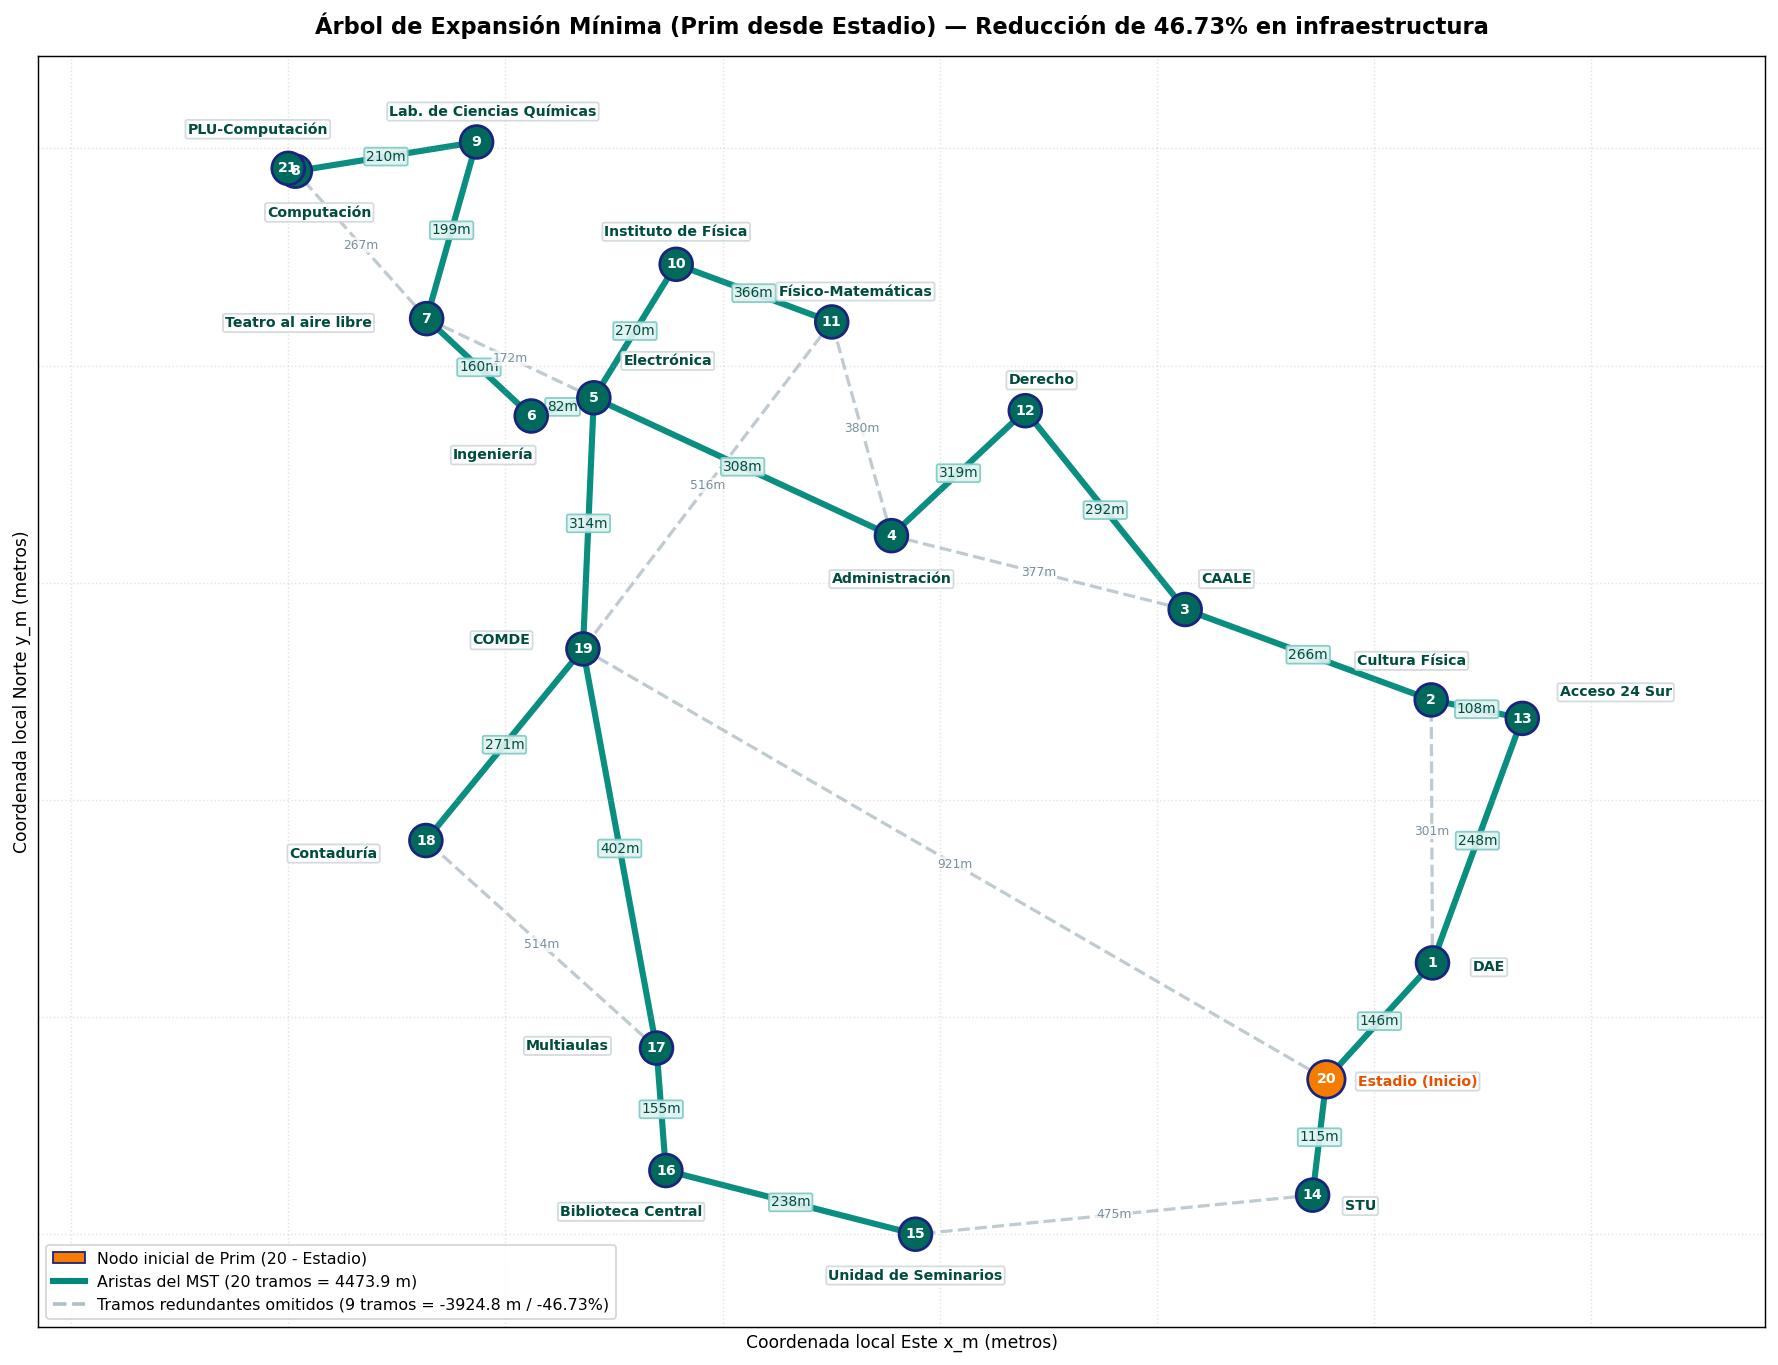

In [56]:
# Árbol de expansión mínima usando algoritmo de Prim con tabla (visitado, distancia, previo)
# Si en la demo se desconecta G, trabajamos sobre la componente conexa principal
if nx.is_connected(G):
    G_mst = G
else:
    comp_mayor = max(nx.connected_components(G), key=len)
    G_mst = G.subgraph(comp_mayor).copy()
    print(f"[Aviso] G no es conexo; se calcula el MST en su componente principal ({len(comp_mayor)} nodos).\n")

# Nodo inicial: 20 (Estadio) si está en la red; si se elimina en la demo, toma el primer nodo del CSV
NODO_INICIAL_PREFERIDO = 20
raiz = NODO_INICIAL_PREFERIDO if NODO_INICIAL_PREFERIDO in G_mst else next(iter(G_mst.nodes()))

def prim_con_tabla(grafo, inicio):
    """Algoritmo de Prim con tabla de visitado, distancia y nodo previo."""
    nodos = list(grafo.nodes())
    visitado = {n: False for n in nodos}
    distancia = {n: float("inf") for n in nodos}
    previo = {n: None for n in nodos}
    orden_visita = []

    distancia[inicio] = 0.0

    for _ in range(len(nodos)):
        # 1. Buscar el nodo NO visitado con menor distancia al árbol actual
        no_visitados = [n for n in nodos if not visitado[n]]
        u = min(no_visitados, key=lambda n: (distancia[n], n))

        # 2. Marcar como visitado
        visitado[u] = True
        orden_visita.append(u)

        # 3. Revisar vecinos no visitados y actualizar si conviene más
        for v in grafo.neighbors(u):
            if not visitado[v]:
                peso = grafo[u][v]["dist_ruta_m"]
                if peso < distancia[v]:
                    distancia[v] = peso
                    previo[v] = u

    # Construcción del árbol MST a partir de la columna 'previo'
    T = nx.Graph()
    for n, attrs in grafo.nodes(data=True):
        T.add_node(n, **attrs)
    for n in nodos:
        p = previo[n]
        if p is not None:
            T.add_edge(p, n, dist_ruta_m=distancia[n])

    return T, visitado, distancia, previo, orden_visita

T_mst, visitado, distancia, previo, orden_visita = prim_con_tabla(G_mst, raiz)

# Validación contra NetworkX y propiedades de árbol
T_ref = nx.minimum_spanning_tree(G_mst, weight="dist_ruta_m", algorithm="prim")
peso_original = sum(d["dist_ruta_m"] for _, _, d in G_mst.edges(data=True))
peso_mst = sum(d["dist_ruta_m"] for _, _, d in T_mst.edges(data=True))
peso_ref = sum(d["dist_ruta_m"] for _, _, d in T_ref.edges(data=True))
ahorro_m = peso_original - peso_mst
reduccion_pct = (ahorro_m / peso_original) * 100.0
aristas_eliminadas = G_mst.number_of_edges() - T_mst.number_of_edges()

print(f"=== ALGORITMO DE PRIM — TABLA FINAL (Inicio: {raiz} - {G_mst.nodes[raiz]['nombre']}) ===")
print(f"{'Paso':>4} | {'ID':>2} | {'Estación':<26} | {'Visitado':^8} | {'Dist. previo (m)':>16} | {'Nodo previo'}")
print("-" * 92)
for paso, nid in enumerate(orden_visita, start=1):
    p = previo[nid]
    prev_str = f"{p:2d} - {G_mst.nodes[p]['nombre']}" if p is not None else "— (Raíz)"
    print(f"{paso:4d} | {nid:2d} | {G_mst.nodes[nid]['nombre']:<26} | {str(visitado[nid]):^8} | {distancia[nid]:16.1f} | {prev_str}")

print("\n=== VALIDACIÓN E IMPACTO DE OPTIMIZACIÓN ===")
print(f"¿Es árbol válido? (conexo y |E|=|V|-1) : {nx.is_tree(T_mst)} (|V|={T_mst.number_of_nodes()}, |E|={T_mst.number_of_edges()})")
print(f"Coincide con nx.minimum_spanning_tree  : {np.isclose(peso_mst, peso_ref)} (Prim manual={peso_mst:.1f} m vs NX={peso_ref:.1f} m)")
print(f"Infraestructura red original G         : {G_mst.number_of_edges()} tramos | {peso_original:.1f} m")
print(f"Infraestructura mínima MST (Prim)      : {T_mst.number_of_edges()} tramos | {peso_mst:.1f} m")
print(f"Tramos redundantes eliminados          : {aristas_eliminadas} tramos (-{100*aristas_eliminadas/G_mst.number_of_edges():.1f}% en número de aristas)")
print(f"Ahorro total en ciclovía               : {ahorro_m:.1f} m ({reduccion_pct:.2f}% de reducción de longitud)")

# Detalle de las aristas descartadas (redundantes)
set_mst = {tuple(sorted(e)) for e in T_mst.edges()}
aristas_fuera = sorted([tuple(sorted((u, v))) for u, v in G_mst.edges() if tuple(sorted((u, v))) not in set_mst])
print("\nTramos redundantes omitidos en el MST:")
for u, v in aristas_fuera:
    print(f"  - {{{u:2d}, {v:2d}}} ({G_mst.nodes[u]['nombre']} <-> {G_mst.nodes[v]['nombre']}) : {G_mst[u][v]['dist_ruta_m']:.1f} m")

# Gráfica del MST resaltado sobre la red original
fig, ax = plt.subplots(figsize=(14, 10.5), dpi=130)

# 1. Aristas originales descartadas (gris punteado)
nx.draw_networkx_edges(
    G_mst, pos, edgelist=aristas_fuera, ax=ax,
    edge_color="#B0BEC5", width=1.8, style="--", alpha=0.8,
)

# 2. Aristas del MST resaltadas
nx.draw_networkx_edges(
    T_mst, pos, ax=ax,
    edge_color="#00897B", width=3.4, alpha=0.96,
)

# Etiquetas de peso en las aristas del MST
mst_labels = {(u, v): f"{d['dist_ruta_m']:.0f}m" for u, v, d in T_mst.edges(data=True)}
nx.draw_networkx_edge_labels(
    T_mst, pos, edge_labels=mst_labels, font_size=7.6, font_color="#004D40",
    rotate=False, bbox=dict(boxstyle="round,pad=0.14", facecolor="#E0F2F1", edgecolor="#80CBC4", alpha=0.92), ax=ax,
)

# Etiquetas tenues en las aristas redundantes
out_labels = {(u, v): f"{G_mst[u][v]['dist_ruta_m']:.0f}m" for u, v in aristas_fuera}
nx.draw_networkx_edge_labels(
    G_mst, pos, edge_labels=out_labels, font_size=6.8, font_color="#78909C",
    rotate=False, bbox=dict(boxstyle="round,pad=0.10", facecolor="white", edgecolor="none", alpha=0.75), ax=ax,
)

# Nodos (raíz Estadio destacada porque de ahí salimos los de CU2)
colores_mst = ["#F57C00" if n == raiz else "#00695C" for n in T_mst.nodes()]
tamanos_mst = [430 if n == raiz else 330 for n in T_mst.nodes()]
nx.draw_networkx_nodes(
    T_mst, pos, ax=ax,
    node_color=colores_mst, edgecolors="#1A237E", linewidths=1.5, node_size=tamanos_mst,
)
nx.draw_networkx_labels(T_mst, pos, ax=ax, font_size=7.8, font_weight="bold", font_color="white")

for nid in T_mst.nodes():
    x, y = pos[nid]
    dx, dy = label_offsets.get(nid, (18, 18))
    etq = f"{G_mst.nodes[nid]['nombre']} (Inicio)" if nid == raiz else G_mst.nodes[nid]["nombre"]
    ax.text(
        x + dx, y + dy, etq,
        fontsize=7.8, fontweight="bold" if nid == raiz else "semibold",
        color="#E65100" if nid == raiz else "#004D40",
        ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="#CFD8DC", alpha=0.9),
    )

leyenda_mst = [
    mpatches.Patch(facecolor="#F57C00", edgecolor="#1A237E", label=f"Nodo inicial de Prim ({raiz} - {G_mst.nodes[raiz]['nombre']})"),
    mlines.Line2D([], [], color="#00897B", linewidth=3.4, label=f"Aristas del MST ({T_mst.number_of_edges()} tramos = {peso_mst:.1f} m)"),
    mlines.Line2D([], [], color="#B0BEC5", linewidth=2.0, linestyle="--", label=f"Tramos redundantes omitidos ({aristas_eliminadas} tramos = -{ahorro_m:.1f} m / -{reduccion_pct:.2f}%)"),
]
ax.legend(handles=leyenda_mst, loc="lower left", frameon=True, fontsize=8.8)
ax.set_title(
    f"Árbol de Expansión Mínima (Prim desde {G_mst.nodes[raiz]['nombre']}) — Reducción de {reduccion_pct:.2f}% en infraestructura",
    fontsize=12.5, fontweight="bold", pad=12,
)
ax.set_xlabel("Coordenada local Este x_m (metros)", fontsize=9.5)
ax.set_ylabel("Coordenada local Norte y_m (metros)", fontsize=9.5)
ax.set_aspect("equal")
ax.set_xlim(-230, 1360)
ax.set_ylim(-85, 1085)
ax.grid(True, linestyle=":", alpha=0.35)
plt.tight_layout()
plt.show()